# Ejercicio 1.05 - Evaluación, Ablación e Interpretabilidad

Este notebook contiene los experimentos finales del sistema de clasificación
multietiqueta de anomalías de rodilla.

Se utiliza EfficientNet-B0 2.5D como arquitectura base, debido a que obtuvo el
mejor desempeño sobre GOLD DEV en la comparación de arquitecturas.

Los experimentos incluyen:

1. Ablación de función de pérdida: Weighted BCE vs Focal Loss.
2. Ablación del plano de MRI: sagital vs axial con supresión de grasa.
3. Selección y justificación del umbral de clasificación.
4. Interpretabilidad mediante Grad-CAM.
5. Evaluación final sobre GOLD HOLDOUT una vez congeladas todas las decisiones.

En este notebook se realizan los experimentos finales del sistema de
clasificación multietiqueta de anomalías de rodilla.

La arquitectura base será EfficientNet-B0 2.5D, ya que obtuvo el mejor
resultado en GOLD DEV:

- AUC macro CNN 2.5D: 0.6614
- AUC macro EfficientNet-B0: 0.7665

La primera ablación evaluará el efecto de la función de pérdida,
comparando Weighted BCE contra Focal Loss bajo las mismas condiciones
de entrenamiento.

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

print(
    "PyTorch:",
    torch.__version__
)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Device:",
    device
)

PyTorch: 2.14.1+cpu
Device: cpu


### Fijamos una semilla

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(
    "Seed:",
    SEED
)

Seed: 42


### Encontrar nuestros archivos

In [3]:
import sys
from pathlib import Path

actual = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        ruta for ruta in [actual, *actual.parents]
        if (ruta / "config" / "config.yaml").is_file()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró config/config.yaml")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import load_config, get_data_root

config = load_config()
DATA_ROOT = get_data_root(config)

# Dataset sagital generado en Notebook 03
IMAGES_PATH = DATA_ROOT / "processed" / "images_2_5d_uint8.npy"
METADATA_PATH = DATA_ROOT / "processed" / "metadata_2_5d.csv"

# Modelo base del Notebook 04
BASELINE_CHECKPOINT = DATA_ROOT / "checkpoint" / "best_efficientnet_2_5d.pth"

# Modelos históricos de las ablaciones
BCE_CHECKPOINT = DATA_ROOT / "checkpoint" / "best_ablacion_bce.pth"
FOCAL_CHECKPOINT = DATA_ROOT / "checkpoint" / "best_ablacion_focal.pth"
AXIAL_CHECKPOINT = DATA_ROOT / "checkpoint" / "best_ablacion_axial_focal.pth"

# Dataset axial de Kaggle
AXIAL_IMAGES_PATH = DATA_ROOT / "processed" / "images_2_5d_axial_uint8.npy"
AXIAL_METADATA_PATH = DATA_ROOT / "processed" / "metadata_2_5d_axial.csv"
AXIAL_MANIFEST_PATH = DATA_ROOT / "manifest" / "manifest_axial_final.csv"

# Salidas nuevas de Notebook 05
OUTPUT_DIR = DATA_ROOT / "processed" / "evaluation_ablation"

archivos = {
    "Imágenes sagitales": IMAGES_PATH,
    "Metadata sagital": METADATA_PATH,
    "EfficientNet base": BASELINE_CHECKPOINT,
    "Checkpoint BCE": BCE_CHECKPOINT,
    "Checkpoint Focal": FOCAL_CHECKPOINT,
    "Checkpoint Axial Focal": AXIAL_CHECKPOINT,
    "Imágenes axiales": AXIAL_IMAGES_PATH,
    "Metadata axial": AXIAL_METADATA_PATH,
    "Manifest axial": AXIAL_MANIFEST_PATH
}

print("Proyecto:", PROJECT_ROOT)
print("Datos:", DATA_ROOT)

print("\nARCHIVOS DISPONIBLES:")
for nombre, ruta in archivos.items():
    estado = "✅" if ruta.is_file() else "❌"
    print(f"{estado} {nombre}: {ruta}")

Proyecto: C:\Users\PC\Documents\knee-mri-weak-supervision
Datos: C:\Users\PC\Documents\RSNA_Knee

ARCHIVOS DISPONIBLES:
✅ Imágenes sagitales: C:\Users\PC\Documents\RSNA_Knee\processed\images_2_5d_uint8.npy
✅ Metadata sagital: C:\Users\PC\Documents\RSNA_Knee\processed\metadata_2_5d.csv
✅ EfficientNet base: C:\Users\PC\Documents\RSNA_Knee\checkpoint\best_efficientnet_2_5d.pth
✅ Checkpoint BCE: C:\Users\PC\Documents\RSNA_Knee\checkpoint\best_ablacion_bce.pth
✅ Checkpoint Focal: C:\Users\PC\Documents\RSNA_Knee\checkpoint\best_ablacion_focal.pth
✅ Checkpoint Axial Focal: C:\Users\PC\Documents\RSNA_Knee\checkpoint\best_ablacion_axial_focal.pth
✅ Imágenes axiales: C:\Users\PC\Documents\RSNA_Knee\processed\images_2_5d_axial_uint8.npy
✅ Metadata axial: C:\Users\PC\Documents\RSNA_Knee\processed\metadata_2_5d_axial.csv
✅ Manifest axial: C:\Users\PC\Documents\RSNA_Knee\manifest\manifest_axial_final.csv


### Cargar imágenes y metadata

In [4]:
# Cargar imágenes y metadatos sagitales
images = np.load(
    IMAGES_PATH,
    mmap_mode="r"
)

metadata = pd.read_csv(
    METADATA_PATH,
    dtype={
        "StudyInstanceUID": str,
        "SeriesInstanceUID": str
    }
)

print("Forma imágenes:", images.shape)
print("Tipo:", images.dtype)
print("Metadata:", metadata.shape)

print("\nDistribución:")
print(metadata["Split"].value_counts())

# Validaciones
assert images.shape == (546, 3, 3, 224, 224)
assert images.dtype == np.uint8
assert len(metadata) == 546

assert metadata["ImageIndex"].tolist() == list(range(546))

assert metadata["StudyInstanceUID"].is_unique

assert metadata["Split"].value_counts().to_dict() == {
    "train": 490,
    "validation": 39,
    "test": 17
}

print("\n✅ Dataset sagital cargado correctamente")

Forma imágenes: (546, 3, 3, 224, 224)
Tipo: uint8
Metadata: (546, 23)

Distribución:
Split
train         490
validation     39
test           17
Name: count, dtype: int64

✅ Dataset sagital cargado correctamente


## Preparación de los datos para la ablación

Se mantienen exactamente los mismos conjuntos utilizados en el experimento base:

- 490 estudios WEAK para entrenamiento.
- 39 estudios GOLD DEV para validación.
- 17 estudios GOLD HOLDOUT reservados para la evaluación final.

El conjunto HOLDOUT no será utilizado durante las ablaciones.

### Definir las 12 etiquetas y comprobar los splits

In [5]:
LABELS = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]

NUM_CLASSES = len(LABELS)

print(
    metadata["Split"]
    .value_counts()
)

print(
    "\nNúmero de clases:",
    NUM_CLASSES
)

Split
train         490
validation     39
test           17
Name: count, dtype: int64

Número de clases: 12


Crear el Dataset y DataLoaders

In [6]:
class KneeDataset(Dataset):

    def __init__(
        self,
        dataframe,
        images,
        labels
    ):

        self.df = (
            dataframe
            .reset_index(drop=True)
        )

        self.images = images
        self.labels = labels


    def __len__(self):

        return len(self.df)


    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_index = int(
            row["ImageIndex"]
        )

        x = (
            self.images[image_index]
            .astype(np.float32)
            / 255.0
        )

        y = (
            row[self.labels]
            .to_numpy(dtype=np.float32)
        )

        return (
            torch.from_numpy(x),
            torch.from_numpy(y)
        )

In [7]:
train_df = metadata[
    metadata["Split"] == "train"
].copy()

val_df = metadata[
    metadata["Split"] == "validation"
].copy()

test_df = metadata[
    metadata["Split"] == "test"
].copy()

print(
    "Train:",
    len(train_df)
)

print(
    "GOLD DEV:",
    len(val_df)
)

print(
    "GOLD HOLDOUT:",
    len(test_df)
)

Train: 490
GOLD DEV: 39
GOLD HOLDOUT: 17


In [8]:
BATCH_SIZE = 8

train_dataset = KneeDataset(
    train_df,
    images,
    LABELS
)

val_dataset = KneeDataset(
    val_df,
    images,
    LABELS
)

test_dataset = KneeDataset(
    test_df,
    images,
    LABELS
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

### Comprobar un batch

In [9]:
X_batch, Y_batch = next(
    iter(train_loader)
)

print(
    "X:",
    X_batch.shape
)

print(
    "Y:",
    Y_batch.shape
)

print(
    "Rango X:",
    X_batch.min().item(),
    X_batch.max().item()
)

print(
    "Valores Y:",
    torch.unique(Y_batch)
)

X: torch.Size([8, 3, 3, 224, 224])
Y: torch.Size([8, 12])
Rango X: 0.0 1.0
Valores Y: tensor([-1.,  0.,  1.])


### Reconstruir pos_weight

In [10]:
pos_weights = []

for label in LABELS:

    values = train_df[label]

    resolved = values[
        values != -1
    ]

    positivos = (
        resolved == 1
    ).sum()

    negativos = (
        resolved == 0
    ).sum()

    weight = (
        negativos / positivos
        if positivos > 0
        else 1.0
    )

    pos_weights.append(
        weight
    )

pos_weight = torch.tensor(
    pos_weights,
    dtype=torch.float32
)

tabla_weights = pd.DataFrame({
    "Label": LABELS,
    "PosWeight": pos_weights
})

display(
    tabla_weights.round(3)
)

,Label,PosWeight
0,ACL,4.022
1,MCL,13.759
2,Medial Meniscus,0.684
3,Lateral Meniscus,2.007
4,Medial OA,1.827
5,Lateral OA,2.010
6,PF OA,1.280
7,Effusion,0.919
8,Synovitis,2.564
9,Baker's,1.810


## Ablación 1: función de pérdida

Se compara la función Weighted BCE utilizada en el modelo base frente a
Weighted Focal Loss.

Para mantener una comparación controlada, ambas pérdidas utilizan los mismos
pesos por clase (`pos_weight`). La única diferencia es que Focal Loss reduce
la contribución de los ejemplos fáciles y enfatiza los ejemplos difíciles.

Las etiquetas con valor -1 corresponden a abstenciones del sistema de weak
labeling y se excluyen del cálculo de ambas pérdidas.

In [11]:
def masked_weighted_bce(
    logits,
    targets,
    pos_weight
):

    mask = (
        targets != -1
    ).float()

    safe_targets = (
        targets.clamp(0, 1)
    )

    loss = F.binary_cross_entropy_with_logits(
        logits,
        safe_targets,
        reduction="none",
        pos_weight=pos_weight
    )

    loss = (
        loss * mask
    ).sum() / mask.sum().clamp_min(1.0)

    return loss

In [12]:
def masked_weighted_focal_loss(
    logits,
    targets,
    pos_weight,
    gamma=2.0
):

    # Ignorar abstenciones (-1)
    mask = (
        targets != -1
    ).float()

    # BCE necesita targets 0/1
    safe_targets = (
        targets.clamp(0, 1)
    )

    # BCE ponderada por desbalance
    bce = F.binary_cross_entropy_with_logits(
        logits,
        safe_targets,
        reduction="none",
        pos_weight=pos_weight
    )

    # Probabilidades
    probs = torch.sigmoid(
        logits
    )

    # Probabilidad asignada a
    # la clase correcta
    p_t = (
        probs * safe_targets
        +
        (1 - probs)
        * (1 - safe_targets)
    )

    # Factor focal
    focal_factor = (
        1 - p_t
    ).pow(gamma)

    loss = (
        focal_factor * bce
    )

    # Eliminar etiquetas -1
    loss = (
        loss * mask
    ).sum() / mask.sum().clamp_min(1.0)

    return loss

### Probemos que ambas funcionan

In [13]:
pos_weight_device = (
    pos_weight.to(device)
)

logits_prueba = torch.randn(
    Y_batch.shape,
    device=device
)

targets_prueba = (
    Y_batch.to(device)
)

loss_bce = masked_weighted_bce(
    logits_prueba,
    targets_prueba,
    pos_weight_device
)

loss_focal = masked_weighted_focal_loss(
    logits_prueba,
    targets_prueba,
    pos_weight_device,
    gamma=2.0
)

print(
    "Weighted BCE:",
    loss_bce.item()
)

print(
    "Weighted Focal:",
    loss_focal.item()
)

Weighted BCE: 0.8989017009735107
Weighted Focal: 0.40123069286346436


### Inicialización común para la ablación

Para aislar el efecto de la función de pérdida, los modelos BCE y Focal
partirán exactamente del mismo estado inicial.

Ambos utilizarán:

- EfficientNet-B0 preentrenada en ImageNet.
- La misma inicialización del clasificador.
- La misma semilla.
- Los mismos conjuntos de entrenamiento y validación.
- Los mismos learning rates y optimizador.
- El mismo criterio de early stopping.

Por tanto, la variable experimental será únicamente la función de pérdida.

### Reconstruimos la misma EfficientNet 2.5D

In [14]:
class EfficientNet2_5D(nn.Module):

    def __init__(
        self,
        num_classes=12,
        dropout=0.3,
        usar_imagenet=True
    ):

        super().__init__()

        if usar_imagenet:
            weights = (
                EfficientNet_B0_Weights
                .IMAGENET1K_V1
            )
        else:
            weights = None

        self.backbone = efficientnet_b0(
            weights=weights
        )

        self.feature_dim = (
            self.backbone
            .classifier[1]
            .in_features
        )

        self.backbone.classifier = (
            nn.Identity()
        )

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(
                self.feature_dim,
                num_classes
            )
        )

        mean = torch.tensor(
            [0.485, 0.456, 0.406],
            dtype=torch.float32
        ).view(
            1, 1, 3, 1, 1
        )

        std = torch.tensor(
            [0.229, 0.224, 0.225],
            dtype=torch.float32
        ).view(
            1, 1, 3, 1, 1
        )

        self.register_buffer(
            "imagenet_mean",
            mean
        )

        self.register_buffer(
            "imagenet_std",
            std
        )


    def forward(self, x):

        B, V, C, H, W = x.shape

        x = (
            x - self.imagenet_mean
        ) / self.imagenet_std

        x = x.reshape(
            B * V,
            C,
            H,
            W
        )

        features = self.backbone(x)

        features = features.reshape(
            B,
            V,
            self.feature_dim
        )

        features = features.mean(
            dim=1
        )

        logits = self.classifier(
            features
        )

        return logits

### Crear UNA inicialización común

In [15]:
SEED_ABLACION = 42

random.seed(SEED_ABLACION)
np.random.seed(SEED_ABLACION)
torch.manual_seed(SEED_ABLACION)

modelo_inicial = EfficientNet2_5D(
    num_classes=NUM_CLASSES,
    usar_imagenet=True
)

estado_inicial = {
    k: v.cpu().clone()
    for k, v
    in modelo_inicial.state_dict().items()
}

print(
    "Estado inicial común creado."
)

print(
    "Parámetros:",
    f"{sum(p.numel() for p in modelo_inicial.parameters()):,}"
)

Estado inicial común creado.
Parámetros: 4,022,920


### Entrenamiento controlado de los experimentos

Los dos experimentos se entrenarán bajo exactamente las mismas condiciones:

- máximo de 20 épocas;
- early stopping con paciencia de 4 épocas;
- learning rate de 1e-4 para el backbone;
- learning rate de 5e-4 para el clasificador;
- AdamW con weight decay de 1e-4;
- selección del mejor checkpoint mediante AUC-ROC macro en GOLD DEV.

Antes de cada entrenamiento se restablece la misma semilla para reducir
variaciones debidas al azar.

### Función de evaluación

In [16]:
def evaluar_auc(
    model,
    loader,
    device,
    labels
):

    model.eval()

    y_true = []
    y_prob = []

    with torch.no_grad():

        for X, y in loader:

            X = X.to(device)

            logits = model(X)

            probs = torch.sigmoid(
                logits
            )

            y_true.append(
                y.numpy()
            )

            y_prob.append(
                probs.cpu().numpy()
            )

    y_true = np.concatenate(
        y_true,
        axis=0
    )

    y_prob = np.concatenate(
        y_prob,
        axis=0
    )

    aucs = {}

    for i, label in enumerate(labels):

        yt = y_true[:, i]
        yp = y_prob[:, i]

        if len(np.unique(yt)) < 2:

            aucs[label] = np.nan

        else:

            aucs[label] = roc_auc_score(
                yt,
                yp
            )

    auc_macro = np.nanmean(
        list(aucs.values())
    )

    return auc_macro, aucs

### Entrenamiento de una época

In [17]:
def entrenar_una_epoca_ablacion(
    model,
    loader,
    optimizer,
    device,
    pos_weight,
    loss_type
):

    model.train()

    loss_total = 0.0
    n_batches = 0

    for X, y in loader:

        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(X)

        if loss_type == "bce":

            loss = masked_weighted_bce(
                logits,
                y,
                pos_weight
            )

        elif loss_type == "focal":

            loss = masked_weighted_focal_loss(
                logits,
                y,
                pos_weight,
                gamma=2.0
            )

        else:

            raise ValueError(
                "loss_type debe ser "
                "'bce' o 'focal'"
            )

        loss.backward()

        optimizer.step()

        loss_total += loss.item()
        n_batches += 1

    return (
        loss_total
        / max(n_batches, 1)
    )

### Función que ejecutará un experimento completo

In [18]:
def ejecutar_experimento(
    nombre,
    loss_type,
    estado_inicial,
    device,
    train_dataset,
    val_loader,
    pos_weight,
    seed=42,
    max_epochs=20,
    patience=4
):

    print(
        "\n" + "=" * 60
    )

    print(
        f"Experimento: {nombre}"
    )

    print(
        "=" * 60
    )

    # -----------------------------
    # Misma semilla
    # -----------------------------

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # -----------------------------
    # DataLoader con mismo orden
    # inicial aleatorio
    # -----------------------------

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader_exp = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=generator
    )

    # -----------------------------
    # Mismo modelo inicial
    # -----------------------------

    model = EfficientNet2_5D(
        num_classes=NUM_CLASSES,
        usar_imagenet=False
    ).to(device)

    model.load_state_dict(
        estado_inicial
    )

    # -----------------------------
    # Mismo optimizador
    # -----------------------------

    optimizer = torch.optim.AdamW(
        [
            {
                "params":
                model.backbone.parameters(),
                "lr": 1e-4
            },
            {
                "params":
                model.classifier.parameters(),
                "lr": 5e-4
            }
        ],
        weight_decay=1e-4
    )

    pos_weight_exp = (
        pos_weight.to(device)
    )

    # -----------------------------
    # Seguimiento
    # -----------------------------

    best_auc = -np.inf
    best_epoch = 0
    epochs_sin_mejora = 0

    historial = []

    best_path = (
        f"/kaggle/working/"
        f"best_{nombre}.pth"
    )

    # -----------------------------
    # Entrenamiento
    # -----------------------------

    for epoch in range(
        1,
        max_epochs + 1
    ):

        train_loss = (
            entrenar_una_epoca_ablacion(
                model,
                train_loader_exp,
                optimizer,
                device,
                pos_weight_exp,
                loss_type
            )
        )

        val_auc, _ = evaluar_auc(
            model,
            val_loader,
            device,
            LABELS
        )

        historial.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_auc_macro": val_auc
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Loss: {train_loss:.4f} | "
            f"Val AUC: {val_auc:.4f}"
        )

        if val_auc > best_auc:

            best_auc = val_auc
            best_epoch = epoch
            epochs_sin_mejora = 0

            torch.save(
                model.state_dict(),
                best_path
            )

            print(
                "   ✓ Mejor modelo guardado"
            )

        else:

            epochs_sin_mejora += 1

        if (
            epochs_sin_mejora
            >= patience
        ):

            print(
                "\nEarly stopping."
            )

            break

    historial = pd.DataFrame(
        historial
    )

    return {
        "nombre": nombre,
        "best_auc": best_auc,
        "best_epoch": best_epoch,
        "best_path": best_path,
        "historial": historial
    }

In [19]:
MODO_ABLACION = "recuperar"  # "entrenar" o "recuperar"

if MODO_ABLACION == "entrenar":

    resultado_bce = ejecutar_experimento(
        nombre="ablacion_bce",
        loss_type="bce",
        estado_inicial=estado_inicial,
        device=device,
        train_dataset=train_dataset,
        val_loader=val_loader,
        pos_weight=pos_weight,
        seed=SEED_ABLACION,
        max_epochs=20,
        patience=4
    )

    print("\nMejor época BCE:", resultado_bce["best_epoch"])
    print("Mejor AUC BCE:", round(resultado_bce["best_auc"], 4))

elif MODO_ABLACION == "recuperar":

    modelo_bce = EfficientNet2_5D(
        num_classes=NUM_CLASSES,
        usar_imagenet=False
    ).to(device)

    modelo_bce.load_state_dict(
        torch.load(
            BCE_CHECKPOINT,
            map_location=device,
            weights_only=True
        )
    )

    modelo_bce.eval()

    auc_bce_local, aucs_bce_local = evaluar_auc(
        modelo_bce,
        val_loader,
        device,
        LABELS
    )

    print("Modelo BCE recuperado correctamente")
    print("AUC macro GOLD DEV:", round(auc_bce_local, 4))

    # Recuperar historial si está disponible
    historial_bce_path = (
        BCE_CHECKPOINT.parent / "historial_ablacion_bce.csv"
    )

    if historial_bce_path.is_file():

        historial_bce_df = pd.read_csv(historial_bce_path)

        idx_mejor = historial_bce_df["val_auc_macro"].idxmax()

        mejor_epoca = int(
            historial_bce_df.loc[idx_mejor, "epoch"]
        )

        historial_bce = historial_bce_df.to_dict("records")

    else:
        historial_bce = []
        mejor_epoca = None

    # Mantener una estructura compatible con entrenamiento
    resultado_bce = {
        "nombre": "ablacion_bce",
        "best_auc": float(auc_bce_local),
        "best_epoch": mejor_epoca,
        "best_path": BCE_CHECKPOINT,
        "historial": historial_bce
    }

    print("\n✅ Resultado BCE reconstruido")
    print("AUC DEV:", round(resultado_bce["best_auc"], 4))
    print("Historial disponible:", len(historial_bce) > 0)

else:
    raise ValueError("MODO_ABLACION debe ser 'entrenar' o 'recuperar'")

Modelo BCE recuperado correctamente
AUC macro GOLD DEV: 0.736

✅ Resultado BCE reconstruido
AUC DEV: 0.736
Historial disponible: False


In [20]:
# ============================================================
# ABLACIÓN FOCAL: ENTRENAR O RECUPERAR
# ============================================================

if MODO_ABLACION == "entrenar":

    resultado_focal = ejecutar_experimento(
        nombre="ablacion_focal",
        loss_type="focal",
        estado_inicial=estado_inicial,
        device=device,
        train_dataset=train_dataset,
        val_loader=val_loader,
        pos_weight=pos_weight,
        seed=SEED_ABLACION,
        max_epochs=20,
        patience=4
    )

    print("\nMejor época Focal:", resultado_focal["best_epoch"])
    print("Mejor AUC Focal:", round(resultado_focal["best_auc"], 4))

elif MODO_ABLACION == "recuperar":

    # Reconstruir la arquitectura
    modelo_focal = EfficientNet2_5D(
        num_classes=NUM_CLASSES,
        usar_imagenet=False
    ).to(device)

    # Recuperar pesos originales de Kaggle
    modelo_focal.load_state_dict(
        torch.load(
            FOCAL_CHECKPOINT,
            map_location=device,
            weights_only=True
        )
    )

    modelo_focal.eval()

    # Recalcular AUC con GOLD DEV
    auc_focal_local, aucs_focal_local = evaluar_auc(
        modelo_focal,
        val_loader,
        device,
        LABELS
    )

    print("Modelo Focal recuperado correctamente")
    print("AUC macro GOLD DEV:", round(auc_focal_local, 4))

    # Recuperar historial, si existe
    historial_focal_path = (
        FOCAL_CHECKPOINT.parent / "historial_ablacion_focal.csv"
    )

    if historial_focal_path.is_file():

        historial_focal = pd.read_csv(historial_focal_path)

        idx_mejor = historial_focal["val_auc_macro"].idxmax()

        mejor_epoca = int(
            historial_focal.loc[idx_mejor, "epoch"]
        )

    else:

        historial_focal = pd.DataFrame(
            columns=["epoch", "train_loss", "val_auc_macro"]
        )

        mejor_epoca = None

    # Estructura compatible con el entrenamiento
    resultado_focal = {
        "nombre": "ablacion_focal",
        "best_auc": float(auc_focal_local),
        "best_epoch": mejor_epoca,
        "best_path": FOCAL_CHECKPOINT,
        "historial": historial_focal
    }

    print("\n✅ Resultado Focal reconstruido")
    print("AUC DEV:", round(resultado_focal["best_auc"], 4))
    print("Historial disponible:", not historial_focal.empty)

else:

    raise ValueError(
        "MODO_ABLACION debe ser 'entrenar' o 'recuperar'"
    )

Modelo Focal recuperado correctamente
AUC macro GOLD DEV: 0.7541

✅ Resultado Focal reconstruido
AUC DEV: 0.7541
Historial disponible: False


### Resultados de la ablación BCE vs Focal Loss

Bajo condiciones controladas, Weighted Focal Loss obtuvo un AUC-ROC macro
de 0.7541 frente a 0.7360 de Weighted BCE.

La mejora absoluta fue de 0.0181 puntos de AUC. Debido a que ambos modelos
partieron de la misma inicialización y utilizaron los mismos datos,
hiperparámetros y criterio de selección, la diferencia observada puede
atribuirse principalmente al cambio en la función de pérdida.

Este resultado se interpreta sobre un conjunto GOLD DEV reducido de
39 estudios, por lo que debe considerarse evidencia experimental y no una
estimación definitiva del rendimiento fuera de muestra.

In [21]:
def obtener_auc_por_label(
    checkpoint_path,
    loader
):

    model = EfficientNet2_5D(
        num_classes=NUM_CLASSES,
        usar_imagenet=False
    ).to(device)

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    model.eval()

    y_true = []
    y_prob = []

    with torch.no_grad():

        for X, y in loader:

            X = X.to(device)

            probs = torch.sigmoid(
                model(X)
            )

            y_true.append(
                y.numpy()
            )

            y_prob.append(
                probs.cpu().numpy()
            )

    y_true = np.concatenate(
        y_true
    )

    y_prob = np.concatenate(
        y_prob
    )

    resultados = []

    for i, label in enumerate(LABELS):

        auc = roc_auc_score(
            y_true[:, i],
            y_prob[:, i]
        )

        resultados.append({
            "Label": label,
            "AUC": auc
        })

    return pd.DataFrame(
        resultados
    )

In [22]:
# Comparar los AUC individuales de BCE y Focal

if MODO_ABLACION == "recuperar":

    auc_bce = pd.DataFrame({
        "Label": LABELS,
        "AUC": [aucs_bce_local[label] for label in LABELS]
    })

    auc_focal = pd.DataFrame({
        "Label": LABELS,
        "AUC": [aucs_focal_local[label] for label in LABELS]
    })

else:

    auc_bce = obtener_auc_por_label(
        resultado_bce["best_path"],
        val_loader
    )

    auc_focal = obtener_auc_por_label(
        resultado_focal["best_path"],
        val_loader
    )

print("✅ AUC por patología recuperados")
print("BCE:", len(auc_bce))
print("Focal:", len(auc_focal))

✅ AUC por patología recuperados
BCE: 12
Focal: 12


In [23]:
comparacion_loss = (
    auc_bce
    .rename(
        columns={
            "AUC": "AUC_BCE"
        }
    )
    .merge(
        auc_focal.rename(
            columns={
                "AUC": "AUC_Focal"
            }
        ),
        on="Label"
    )
)

comparacion_loss[
    "Diferencia"
] = (
    comparacion_loss["AUC_Focal"]
    -
    comparacion_loss["AUC_BCE"]
)

comparacion_loss = (
    comparacion_loss
    .sort_values(
        "Diferencia",
        ascending=False
    )
)

display(
    comparacion_loss.round(4)
)

,Label,AUC_BCE,AUC_Focal,Diferencia
11,Fracture,0.5093,0.6512,0.1420
3,Lateral Meniscus,0.7283,0.8043,0.0761
9,Baker's,0.7500,0.8226,0.0726
2,Medial Meniscus,0.7326,0.8021,0.0695
4,Medial OA,0.8138,0.8552,0.0414
0,ACL,0.7283,0.7527,0.0245
6,PF OA,0.8462,0.8521,0.0059
10,Contusion,0.6657,0.6568,-0.0089
8,Synovitis,0.7593,0.7460,-0.0132
7,Effusion,0.8642,0.8395,-0.0247


In [24]:
# ============================================================
# GUARDAR RESULTADOS DE LA ABLACIÓN 1
# ============================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Guardar los historiales reales cuando estén disponibles
for nombre, resultado in [
    ("bce", resultado_bce),
    ("focal", resultado_focal)
]:

    historial = resultado["historial"]

    if historial is not None and len(historial) > 0:

        historial_df = pd.DataFrame(historial)

        ruta_historial = (
            OUTPUT_DIR / f"historial_ablacion_{nombre}.csv"
        )

        historial_df.to_csv(
            ruta_historial,
            index=False
        )

        print(f"✅ Historial {nombre} guardado")

    else:

        print(f"Historial {nombre} no disponible; no se genera CSV")


# Guardar la comparación BCE vs Focal
ruta_comparacion = (
    OUTPUT_DIR / "comparacion_bce_vs_focal.csv"
)

comparacion_loss.to_csv(
    ruta_comparacion,
    index=False
)

print("\n✅ Resultados de la Ablación 1 guardados")
print("Comparación:", ruta_comparacion)
print("Patologías:", len(comparacion_loss))

print("\nAUC macro GOLD DEV:")
print("BCE:", round(resultado_bce["best_auc"], 4))
print("Focal:", round(resultado_focal["best_auc"], 4))

Historial bce no disponible; no se genera CSV
Historial focal no disponible; no se genera CSV

✅ Resultados de la Ablación 1 guardados
Comparación: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\comparacion_bce_vs_focal.csv
Patologías: 12

AUC macro GOLD DEV:
BCE: 0.736
Focal: 0.7541


## Ablación 2: plano de MRI

La segunda ablación evalúa el efecto del plano de adquisición de MRI.

Se compara el plano sagital utilizado en los experimentos anteriores frente
al plano axial, manteniendo constante el conjunto de estudios, las etiquetas,
el preprocesamiento 2.5D y la arquitectura de clasificación.

Para evitar confundir el efecto del plano con diferencias en la población,
se utilizarán los mismos estudios siempre que exista una serie axial adecuada.

In [25]:
from pathlib import Path
import pandas as pd

# Ruta local configurada en nuestro proyecto
TRAIN_SERIES_CSV = (
    DATA_ROOT / config["data"]["train_series_csv"]
)

print(
    "Existe train_series.csv:",
    TRAIN_SERIES_CSV.exists()
)

series_df = pd.read_csv(
    TRAIN_SERIES_CSV,
    dtype={
        "StudyInstanceUID": str,
        "SeriesInstanceUID": str
    }
)

print("Shape:", series_df.shape)
print("Columnas:", series_df.columns.tolist())

display(series_df.head())

Existe train_series.csv: True
Shape: (24371, 5)
Columnas: ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.23084836536722595275...,0,0,Coronal
3,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,1,1,Coronal
4,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.75714899997203615784...,0,0,Sagittal


In [26]:
study_uids = set(
    metadata["StudyInstanceUID"]
    .astype(str)
)

axial_candidates = series_df[
    (series_df["Anatomical_Plane"] == "Axial")
    &
    (series_df["Fluid_Sensitive"] == 1)
    &
    (series_df["Fat_Suppression"] == 1)
    &
    (
        series_df["StudyInstanceUID"]
        .astype(str)
        .isin(study_uids)
    )
].copy()

print(
    "Series axiales candidatas:",
    len(axial_candidates)
)

print(
    "Estudios con axial:",
    axial_candidates[
        "StudyInstanceUID"
    ].nunique()
)

print(
    "Estudios esperados:",
    len(study_uids)
)

Series axiales candidatas: 580
Estudios con axial: 546
Estudios esperados: 546


In [27]:
series_por_estudio = (
    axial_candidates
    .groupby("StudyInstanceUID")
    .size()
)

print(
    series_por_estudio
    .value_counts()
    .sort_index()
)

print(
    "\nEstudios con más de una "
    "serie axial candidata:",
    (series_por_estudio > 1).sum()
)

1    514
2     30
3      2
Name: count, dtype: int64

Estudios con más de una serie axial candidata: 32


In [28]:
multi_studies = (
    series_por_estudio[
        series_por_estudio > 1
    ]
    .index
)

axial_multi = (
    axial_candidates[
        axial_candidates[
            "StudyInstanceUID"
        ].isin(multi_studies)
    ]
    .sort_values([
        "StudyInstanceUID",
        "SeriesInstanceUID"
    ])
)

print(
    "Estudios múltiples:",
    len(multi_studies)
)

print(
    "Series involucradas:",
    len(axial_multi)
)

display(
    axial_multi.head(50)
)

Estudios múltiples: 32
Series involucradas: 66


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane
353,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.25511961362790207336...,1,1,Axial
358,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.71876353677262220297...,1,1,Axial
440,1.2.826.0.1.3680043.8.498.10211034309703220222...,1.2.826.0.1.3680043.8.498.31764336028067398645...,1,1,Axial
441,1.2.826.0.1.3680043.8.498.10211034309703220222...,1.2.826.0.1.3680043.8.498.32661347065766832539...,1,1,Axial
444,1.2.826.0.1.3680043.8.498.10211034309703220222...,1.2.826.0.1.3680043.8.498.54609779635707026936...,1,1,Axial
613,1.2.826.0.1.3680043.8.498.10306159113324811538...,1.2.826.0.1.3680043.8.498.19770471468778499025...,1,1,Axial
616,1.2.826.0.1.3680043.8.498.10306159113324811538...,1.2.826.0.1.3680043.8.498.52935759841844767282...,1,1,Axial
3155,1.2.826.0.1.3680043.8.498.11641866550826314411...,1.2.826.0.1.3680043.8.498.82082186978650944031...,1,1,Axial
3156,1.2.826.0.1.3680043.8.498.11641866550826314411...,1.2.826.0.1.3680043.8.498.86752465881950402881...,1,1,Axial
3346,1.2.826.0.1.3680043.8.498.11752091432368750506...,1.2.826.0.1.3680043.8.498.27121009003564950503...,1,1,Axial


### Selección de una única serie axial por estudio

La mayoría de los estudios posee una única serie axial compatible con los
criterios seleccionados. Sin embargo, algunos estudios contienen múltiples
series candidatas.

Para evitar una selección arbitraria, se inspeccionan metadatos DICOM como
descripción de serie, protocolo, TE, TR, número de cortes, grosor y separación
entre cortes. A partir de esta información se definirá una regla reproducible
para seleccionar una única serie por estudio.

In [29]:
import pydicom
import numpy as np
from pathlib import Path

TRAIN_SERIES_DIR = (
    DATA_ROOT / config["data"]["raw"]["axial"]
)

print("Directorio DICOM axial:", TRAIN_SERIES_DIR)
print("Existe:", TRAIN_SERIES_DIR.is_dir())

def leer_header_serie(study_uid,series_uid):

    serie_dir = (
        TRAIN_SERIES_DIR
        / str(study_uid)
        / str(series_uid)
    )

    if not serie_dir.is_dir():
        return None

    archivos = sorted(
        [
            p for p in serie_dir.iterdir()
            if p.is_file()
        ]
    )

    if len(archivos) == 0:
        return None

    ds = pydicom.dcmread(
        archivos[0],
        stop_before_pixels=True,
        force=True
    )

    return {
        "StudyInstanceUID": str(study_uid),
        "SeriesInstanceUID": str(series_uid),

        "SeriesDescription": str(
            getattr(
                ds,
                "SeriesDescription",
                ""
            )
        ),

        "ProtocolName": str(
            getattr(
                ds,
                "ProtocolName",
                ""
            )
        ),

        "TR": getattr(
            ds,
            "RepetitionTime",
            np.nan
        ),

        "TE": getattr(
            ds,
            "EchoTime",
            np.nan
        ),

        "SliceThickness": getattr(
            ds,
            "SliceThickness",
            np.nan
        ),

        "SpacingBetweenSlices": getattr(
            ds,
            "SpacingBetweenSlices",
            np.nan
        ),

        "Rows": getattr(
            ds,
            "Rows",
            np.nan
        ),

        "Columns": getattr(
            ds,
            "Columns",
            np.nan
        ),

        "N_Slices": len(archivos)
    }

Directorio DICOM axial: C:\Users\PC\Documents\RSNA_Knee\raw\axial
Existe: True


In [30]:
headers_axial_multi = []

for _, row in axial_multi.iterrows():

    info = leer_header_serie(
        row["StudyInstanceUID"],
        row["SeriesInstanceUID"]
    )

    if info is not None:
        headers_axial_multi.append(info)

headers_axial_multi = pd.DataFrame(
    headers_axial_multi
)

print(
    "Series inspeccionadas:",
    len(headers_axial_multi)
)

display(headers_axial_multi)

Series inspeccionadas: 32


,StudyInstanceUID,SeriesInstanceUID,SeriesDescription,ProtocolName,TR,TE,SliceThickness,SpacingBetweenSlices,Rows,Columns,N_Slices
0,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.71876353677262220297...,RT.Tra_T2W_TSE_SPAIR,,3987.607422,83.008,3.0,3.300,640,640,40
1,1.2.826.0.1.3680043.8.498.10211034309703220222...,1.2.826.0.1.3680043.8.498.31764336028067398645...,Ax PD FSE FS DL,,5559.000000,30.944,3.0,4.000,1024,1024,40
2,1.2.826.0.1.3680043.8.498.10306159113324811538...,1.2.826.0.1.3680043.8.498.19770471468778499025...,Ax T2 FSE FS_sm_AIRS,,4286.000000,54.240,3.0,3.500,640,640,40
3,1.2.826.0.1.3680043.8.498.11641866550826314411...,1.2.826.0.1.3680043.8.498.82082186978650944031...,,,4060.000000,33.000,3.0,4.000,884,832,33
4,1.2.826.0.1.3680043.8.498.11752091432368750506...,1.2.826.0.1.3680043.8.498.27121009003564950503...,DummySeriesDesc!,,2640.000000,41.000,3.0,3.300,448,462,36
5,1.2.826.0.1.3680043.8.498.12303161232396569915...,1.2.826.0.1.3680043.8.498.38602704360960995449...,Axial PD FatSat,,2124.000000,36.000,4.0,4.500,448,448,32
6,1.2.826.0.1.3680043.8.498.12448079646359892252...,1.2.826.0.1.3680043.8.498.35003530834353727317...,AXI T2 SPIR SENSE,,1999.999756,45.000,2.5,3.850,432,432,12
7,1.2.826.0.1.3680043.8.498.13035632998746261521...,1.2.826.0.1.3680043.8.498.26599108015020079164...,PDW_TSE_SPAIR_Tra,,3675.720703,30.000,3.0,3.300,640,640,36
8,1.2.826.0.1.3680043.8.498.27644321991318957631...,1.2.826.0.1.3680043.8.498.11613477208365641992...,AX T2 FS_sm_AIRS,,4900.000000,53.000,4.0,4.520,640,640,36
9,1.2.826.0.1.3680043.8.498.40239104167848425290...,1.2.826.0.1.3680043.8.498.10321362786209717535...,Ax T2 FSE FS_sm_AIRS,,3392.000000,47.952,3.0,3.500,640,640,34


In [31]:
display(
    headers_axial_multi[
        [
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SeriesDescription",
            "ProtocolName",
            "TR",
            "TE",
            "SliceThickness",
            "SpacingBetweenSlices",
            "N_Slices"
        ]
    ]
)

,StudyInstanceUID,SeriesInstanceUID,SeriesDescription,ProtocolName,TR,TE,SliceThickness,SpacingBetweenSlices,N_Slices
0,1.2.826.0.1.3680043.8.498.10170898615867673028...,1.2.826.0.1.3680043.8.498.71876353677262220297...,RT.Tra_T2W_TSE_SPAIR,,3987.607422,83.008,3.0,3.300,40
1,1.2.826.0.1.3680043.8.498.10211034309703220222...,1.2.826.0.1.3680043.8.498.31764336028067398645...,Ax PD FSE FS DL,,5559.000000,30.944,3.0,4.000,40
2,1.2.826.0.1.3680043.8.498.10306159113324811538...,1.2.826.0.1.3680043.8.498.19770471468778499025...,Ax T2 FSE FS_sm_AIRS,,4286.000000,54.240,3.0,3.500,40
3,1.2.826.0.1.3680043.8.498.11641866550826314411...,1.2.826.0.1.3680043.8.498.82082186978650944031...,,,4060.000000,33.000,3.0,4.000,33
4,1.2.826.0.1.3680043.8.498.11752091432368750506...,1.2.826.0.1.3680043.8.498.27121009003564950503...,DummySeriesDesc!,,2640.000000,41.000,3.0,3.300,36
5,1.2.826.0.1.3680043.8.498.12303161232396569915...,1.2.826.0.1.3680043.8.498.38602704360960995449...,Axial PD FatSat,,2124.000000,36.000,4.0,4.500,32
6,1.2.826.0.1.3680043.8.498.12448079646359892252...,1.2.826.0.1.3680043.8.498.35003530834353727317...,AXI T2 SPIR SENSE,,1999.999756,45.000,2.5,3.850,12
7,1.2.826.0.1.3680043.8.498.13035632998746261521...,1.2.826.0.1.3680043.8.498.26599108015020079164...,PDW_TSE_SPAIR_Tra,,3675.720703,30.000,3.0,3.300,36
8,1.2.826.0.1.3680043.8.498.27644321991318957631...,1.2.826.0.1.3680043.8.498.11613477208365641992...,AX T2 FS_sm_AIRS,,4900.000000,53.000,4.0,4.520,36
9,1.2.826.0.1.3680043.8.498.40239104167848425290...,1.2.826.0.1.3680043.8.498.10321362786209717535...,Ax T2 FSE FS_sm_AIRS,,3392.000000,47.952,3.0,3.500,34


In [32]:
tabla_revision = (
    headers_axial_multi[
        [
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SeriesDescription",
            "TR",
            "TE",
            "SliceThickness",
            "SpacingBetweenSlices",
            "Rows",
            "Columns",
            "N_Slices"
        ]
    ]
    .copy()
)

# Identificadores cortos para que sea legible
tabla_revision["StudyShort"] = (
    tabla_revision["StudyInstanceUID"]
    .str[-12:]
)

tabla_revision["SeriesShort"] = (
    tabla_revision["SeriesInstanceUID"]
    .str[-12:]
)

tabla_revision = tabla_revision[
    [
        "StudyShort",
        "SeriesShort",
        "SeriesDescription",
        "TR",
        "TE",
        "SliceThickness",
        "SpacingBetweenSlices",
        "Rows",
        "Columns",
        "N_Slices"
    ]
]

with pd.option_context(
    "display.max_rows", 100,
    "display.max_colwidth", 50
):
    display(tabla_revision)

,StudyShort,SeriesShort,SeriesDescription,TR,TE,SliceThickness,SpacingBetweenSlices,Rows,Columns,N_Slices
0,248839028269,243928050962,RT.Tra_T2W_TSE_SPAIR,3987.607422,83.008,3.0,3.300,640,640,40
1,582770542129,813842595776,Ax PD FSE FS DL,5559.000000,30.944,3.0,4.000,1024,1024,40
2,080836752052,468366899017,Ax T2 FSE FS_sm_AIRS,4286.000000,54.240,3.0,3.500,640,640,40
3,478180861612,497309408809,,4060.000000,33.000,3.0,4.000,884,832,33
4,028559788225,429664607941,DummySeriesDesc!,2640.000000,41.000,3.0,3.300,448,462,36
5,761728884199,305001764631,Axial PD FatSat,2124.000000,36.000,4.0,4.500,448,448,32
6,258836556945,901402690335,AXI T2 SPIR SENSE,1999.999756,45.000,2.5,3.850,432,432,12
7,720102873141,712274705560,PDW_TSE_SPAIR_Tra,3675.720703,30.000,3.0,3.300,640,640,36
8,895883331622,910614440503,AX T2 FS_sm_AIRS,4900.000000,53.000,4.0,4.520,640,640,36
9,013326180693,778379574447,Ax T2 FSE FS_sm_AIRS,3392.000000,47.952,3.0,3.500,640,640,34


In [33]:
desc = (
    headers_axial_multi[
        "SeriesDescription"
    ]
    .fillna("")
    .str.upper()
)

patrones = [
    "ORIG",
    "REPEAT",
    "REP",
    "SCOUT",
    "LOCALIZER",
    "LOWER",
    "UPPER",
    "WATER",
    "FAT"
]

for patron in patrones:

    encontrados = (
        headers_axial_multi[
            desc.str.contains(
                patron,
                regex=False
            )
        ]
    )

    print(
        f"{patron}:",
        len(encontrados)
    )

ORIG: 0
REPEAT: 0
REP: 0
SCOUT: 0
LOCALIZER: 0
LOWER: 0
UPPER: 0
WATER: 1
FAT: 5


### Regla de selección axial

Cuando un estudio posee múltiples series candidatas:

1. Penalizar series identificadas como ORIG o REPEAT cuando existe otra candidata válida.
2. Penalizar series cuya descripción indique plano coronal cuando exista una alternativa axial/transversal.
3. Preferir adquisiciones originales frente a reconstrucciones MPR.
4. Priorizar secuencias explícitas PD/DP, seguidas de T2/STIR.
5. Para descripciones ambiguas, usar TE como criterio reproducible:
   TE <= 45 ms → PD-like; TE >= 50 ms → T2-like.
6. Como desempate, favorecer mayor número de cortes, spacing adecuado y mayor resolución.
7. Si las candidatas continúan siendo equivalentes, usar SeriesInstanceUID
   como desempate determinista.

### Leer headers de las 580 candidatas

In [34]:
headers_axial_all = []

for _, row in axial_candidates.iterrows():

    info = leer_header_serie(
        row["StudyInstanceUID"],
        row["SeriesInstanceUID"]
    )

    if info is not None:
        headers_axial_all.append(info)

axial_inventory = pd.DataFrame(
    headers_axial_all
)

print(
    "Series candidatas:",
    len(axial_candidates)
)

print(
    "Headers obtenidos:",
    len(axial_inventory)
)

print(
    "Estudios:",
    axial_inventory[
        "StudyInstanceUID"
    ].nunique()
)

Series candidatas: 580
Headers obtenidos: 546
Estudios: 546


In [35]:
import re

def clasificar_secuencia_axial(row):

    texto = (
        str(row["SeriesDescription"])
        + " "
        + str(row["ProtocolName"])
    ).upper()

    te = row["TE"]

    # PD / DP explícito
    if re.search(
        r"(?:^|[^A-Z])"
        r"(?:PD|PDW|DP)"
        r"(?:[^A-Z]|$)",
        texto
    ):
        return "PD", 0

    # T2 / STIR explícito
    if re.search(
        r"(?:^|[^A-Z])"
        r"(?:T2|T2W|STIR)"
        r"(?:[^A-Z]|$)",
        texto
    ):
        return "T2", 1

    # Heurística por TE
    if pd.notna(te):

        te = float(te)

        if te <= 45:
            return "PD_like", 2

        if te >= 50:
            return "T2_like", 3

    return "AMBIGUO", 4

In [36]:
clasificacion = axial_inventory.apply(
    clasificar_secuencia_axial,
    axis=1
)

axial_inventory[
    "Tipo_Axial"
] = [
    x[0]
    for x in clasificacion
]

axial_inventory[
    "SeqRank"
] = [
    x[1]
    for x in clasificacion
]

### Crear las penalizaciones

In [37]:
desc_upper = (
    axial_inventory[
        "SeriesDescription"
    ]
    .fillna("")
    .str.upper()
)

# ORIG / REPEAT
axial_inventory["PenaltyRepeat"] = (
    desc_upper.str.contains(
        r"ORIG|REPEAT|REPEATED",
        regex=True
    )
    .astype(int)
)

# Descripción aparentemente coronal
axial_inventory["PenaltyCoronal"] = (
    desc_upper.str.contains(
        r"(?:^|[^A-Z])COR(?:[^A-Z]|$)",
        regex=True
    )
    .astype(int)
)

# Reconstrucción MPR
axial_inventory["PenaltyMPR"] = (
    desc_upper.str.contains(
        "MPR",
        regex=False
    )
    .astype(int)
)

# Preferencia por descripción axial/transversal explícita
axial_inventory["AxialExplicit"] = (
    desc_upper.str.contains(
        r"(?:^|[^A-Z])"
        r"(?:AX|AXI|AXIAL|TRA)"
        r"(?:[^A-Z]|$)",
        regex=True
    )
)

axial_inventory[
    "PenaltyNoAxial"
] = (
    ~axial_inventory[
        "AxialExplicit"
    ]
).astype(int)

In [38]:
axial_inventory[
    "SpacingDiff"
] = (
    pd.to_numeric(
        axial_inventory[
            "SpacingBetweenSlices"
        ],
        errors="coerce"
    )
    - 3.5
).abs()

axial_inventory[
    "Resolution"
] = (
    axial_inventory["Rows"]
    *
    axial_inventory["Columns"]
)

# En pares prácticamente idénticos,
# una reconstrucción WATER es preferible
# como representación fat-suppressed.
axial_inventory[
    "WaterRank"
] = (
    ~desc_upper.str.contains(
        "WATER",
        regex=False
    )
).astype(int)

### Elegir la ganadora de cada estudio

In [39]:
axial_ranked = (
    axial_inventory
    .sort_values(
        by=[
            "StudyInstanceUID",
            "PenaltyRepeat",
            "PenaltyCoronal",
            "PenaltyMPR",
            "PenaltyNoAxial",
            "SeqRank",
            "N_Slices",
            "SpacingDiff",
            "Resolution",
            "WaterRank",
            "SeriesInstanceUID"
        ],
        ascending=[
            True,   # Study
            True,   # no repeat/orig
            True,   # no coronal
            True,   # no MPR
            True,   # axial explícito
            True,   # PD -> T2 -> like
            False,  # más cortes
            True,   # spacing cercano
            False,  # más resolución
            True,   # water como desempate
            True    # UID determinista
        ]
    )
)

axial_selected = (
    axial_ranked
    .drop_duplicates(
        subset="StudyInstanceUID",
        keep="first"
    )
    .copy()
)

print(
    "Series seleccionadas:",
    len(axial_selected)
)

print(
    "Estudios únicos:",
    axial_selected[
        "StudyInstanceUID"
    ].nunique()
)

print(
    "\nTipo de secuencia:"
)

print(
    axial_selected[
        "Tipo_Axial"
    ].value_counts()
)

Series seleccionadas: 546
Estudios únicos: 546

Tipo de secuencia:
Tipo_Axial
PD         194
T2         190
PD_like    138
T2_like     24
Name: count, dtype: int64


Antes hacemos una última inspección solamente sobre los 32 estudios conflictivos:

In [40]:
revision_seleccion = axial_selected[
    axial_selected[
        "StudyInstanceUID"
    ].isin(multi_studies)
].copy()

revision_seleccion[
    "StudyShort"
] = (
    revision_seleccion[
        "StudyInstanceUID"
    ]
    .str[-12:]
)

display(
    revision_seleccion[
        [
            "StudyShort",
            "SeriesDescription",
            "Tipo_Axial",
            "TE",
            "SliceThickness",
            "SpacingBetweenSlices",
            "N_Slices",
            "Rows",
            "Columns"
        ]
    ].sort_values(
        "StudyShort"
    )
)

,StudyShort,SeriesDescription,Tipo_Axial,TE,SliceThickness,SpacingBetweenSlices,N_Slices,Rows,Columns
268,013326180693,Ax T2 FSE FS_sm_AIRS,T2,47.952,3.0,3.500,34,640,640
65,028559788225,DummySeriesDesc!,PD_like,41.000,3.0,3.300,36,448,462
465,064495044195,Ax T2 FSE FS,T2,61.008,3.0,3.500,42,256,256
17,080836752052,Ax T2 FSE FS_sm_AIRS,T2,54.240,3.0,3.500,40,640,640
270,088902000849,pd_tse_fs_tra_320,PD,19.000,3.5,4.550,30,768,768
413,120667484813,Axial PD FatSat,PD,36.000,4.0,4.500,30,448,448
531,162110963091,DummySeriesDesc!,PD_like,30.000,3.0,3.300,35,448,448
534,225439854460,Water: SMART FAT,T2_like,51.600,3.5,4.000,30,512,512
8,248839028269,RT.Tra_T2W_TSE_SPAIR,T2,83.008,3.0,3.300,40,640,640
372,252110447010,Ax PD FSE FS DL,PD,31.008,3.0,4.000,40,1024,1024


### Manifest axial final

Después de aplicar la regla de selección se obtuvo una única serie axial por
cada uno de los 546 estudios.

Este manifest se congela antes del preprocesamiento para garantizar que la
comparación sagital vs axial utilice una selección reproducible de series.

In [41]:
manifest_axial = axial_selected[
    [
        "StudyInstanceUID",
        "SeriesInstanceUID",
        "SeriesDescription",
        "ProtocolName",
        "Tipo_Axial",
        "TR",
        "TE",
        "SliceThickness",
        "SpacingBetweenSlices",
        "Rows",
        "Columns",
        "N_Slices"
    ]
].copy()

# Incorporamos Split y etiquetas
columnas_metadata = [
    "StudyInstanceUID",
    "Split"
] + LABELS

manifest_axial = manifest_axial.merge(
    metadata[columnas_metadata],
    on="StudyInstanceUID",
    how="left",
    validate="one_to_one"
)

print(
    "Filas:",
    len(manifest_axial)
)

print(
    "Estudios únicos:",
    manifest_axial["StudyInstanceUID"].nunique()
)

print(
    "\nSplits:"
)

print(
    manifest_axial["Split"].value_counts()
)

print(
    "\nEtiquetas faltantes:",
    manifest_axial[LABELS]
    .isna()
    .sum()
    .sum()
)

display(
    manifest_axial.head()
)

Filas: 546
Estudios únicos: 546

Splits:
Split
train         490
validation     39
test           17
Name: count, dtype: int64

Etiquetas faltantes: 0


,StudyInstanceUID,SeriesInstanceUID,SeriesDescription,ProtocolName,Tipo_Axial,TR,TE,SliceThickness,SpacingBetweenSlices,Rows,...,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10029520033957968044...,1.2.826.0.1.3680043.8.498.10138400860303228304...,LT_t2_tse_fs_tra,,T2,4110.000000,61.0,3.0,3.900,640,...,1,1,-1,-1,-1,1,1,-1,1,-1
1,1.2.826.0.1.3680043.8.498.10061120822929703004...,1.2.826.0.1.3680043.8.498.76206109519289930878...,PDW_SPAIR,,PD,4876.232422,30.0,3.0,3.500,560,...,1,1,-1,-1,-1,1,-1,1,-1,-1
2,1.2.826.0.1.3680043.8.498.10087350795575215080...,1.2.826.0.1.3680043.8.498.22083524570800997810...,DummySeriesDesc!,,PD_like,2472.388428,30.0,4.0,4.400,512,...,-1,-1,0,0,0,0,0,0,0,0
3,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.67495435033389756963...,pd_tse_fs_tra,,PD,4240.000000,40.0,3.5,4.025,320,...,0,0,0,0,1,1,0,0,0,0
4,1.2.826.0.1.3680043.8.498.10155611590208164695...,1.2.826.0.1.3680043.8.498.71632516016159079115...,RT.AX T2W_SPAIR,,T2,3521.530518,60.0,3.0,3.300,528,...,-1,1,-1,0,0,0,0,0,0,0


In [42]:
# Comparar selección local contra manifiesto original de Kaggle

historico = pd.read_csv(
    AXIAL_MANIFEST_PATH,
    dtype={
        "StudyInstanceUID": str,
        "SeriesInstanceUID": str
    }
)

nuevo = manifest_axial[
    ["StudyInstanceUID", "SeriesInstanceUID"]
].copy()

anterior = historico[
    ["StudyInstanceUID", "SeriesInstanceUID"]
].copy()

comparacion_manifest = nuevo.merge(
    anterior,
    on="StudyInstanceUID",
    how="outer",
    validate="one_to_one",
    suffixes=("_local", "_kaggle"),
    indicator=True
)

diferencias = comparacion_manifest[
    (comparacion_manifest["_merge"] != "both")
    |
    (
        comparacion_manifest["SeriesInstanceUID_local"]
        != comparacion_manifest["SeriesInstanceUID_kaggle"]
    )
]

print("Estudios locales:", len(nuevo))
print("Estudios Kaggle:", len(anterior))
print("Diferencias de selección:", len(diferencias))

if len(diferencias) == 0:
    print("✅ Selección axial idéntica a Kaggle")
else:
    print("⚠️ Se encontraron diferencias")
    display(diferencias.head(10))

Estudios locales: 546
Estudios Kaggle: 546
Diferencias de selección: 0
✅ Selección axial idéntica a Kaggle


In [43]:
# Guardar manifiesto axial generado en Windows

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MANIFEST_AXIAL_GENERADO = (
    OUTPUT_DIR / "manifest_axial_final.csv"
)

manifest_axial.to_csv(
    MANIFEST_AXIAL_GENERADO,
    index=False
)

print("Manifest axial guardado:", MANIFEST_AXIAL_GENERADO)

Manifest axial guardado: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\manifest_axial_final.csv


### Preprocesamiento axial 2.5D

Para realizar una comparación controlada con el plano sagital, las series
axiales se procesarán utilizando exactamente la misma estrategia 2.5D:

- ordenamiento espacial de cortes DICOM;
- normalización robusta de intensidades;
- remuestreo únicamente en profundidad a 3.5 mm;
- redimensionamiento a 224 × 224 píxeles;
- selección de vistas relativas en 30 %, 50 % y 70 %;
- tres cortes contiguos por vista.

Cada estudio producirá un tensor de forma `(3, 3, 224, 224)`.

In [44]:
from pathlib import Path

TRAIN_SERIES_DIR = (
    DATA_ROOT / config["data"]["raw"]["axial"]
)

rutas_axiales = []

faltantes = []

for _, row in manifest_axial.iterrows():

    ruta = (
        TRAIN_SERIES_DIR
        / str(row["StudyInstanceUID"])
        / str(row["SeriesInstanceUID"])
    )

    if ruta.exists():
        rutas_axiales.append(ruta)

    else:
        faltantes.append({
            "StudyInstanceUID":
                row["StudyInstanceUID"],

            "SeriesInstanceUID":
                row["SeriesInstanceUID"]
        })

print(
    "Series encontradas:",
    len(rutas_axiales)
)

print(
    "Series faltantes:",
    len(faltantes)
)

Series encontradas: 546
Series faltantes: 0


In [45]:
import numpy as np
import cv2
import pydicom

from scipy.ndimage import zoom
from pathlib import Path

In [46]:
def cargar_serie_dicom(serie_dir):

    archivos = sorted(
        [
            p for p in Path(serie_dir).iterdir()
            if p.is_file()
        ]
    )

    slices = []

    for archivo in archivos:

        ds = pydicom.dcmread(
            archivo,
            force=True
        )

        img = ds.pixel_array.astype(
            np.float32
        )

        slope = float(
            getattr(
                ds,
                "RescaleSlope",
                1.0
            )
        )

        intercept = float(
            getattr(
                ds,
                "RescaleIntercept",
                0.0
            )
        )

        img = (
            img * slope
            + intercept
        )

        # Inversión MONOCHROME1
        if getattr(
            ds,
            "PhotometricInterpretation",
            ""
        ) == "MONOCHROME1":

            img = img.max() - img

        # Posición espacial
        posicion = None

        if (
            hasattr(
                ds,
                "ImagePositionPatient"
            )
            and hasattr(
                ds,
                "ImageOrientationPatient"
            )
        ):

            ipp = np.array(
                ds.ImagePositionPatient,
                dtype=float
            )

            iop = np.array(
                ds.ImageOrientationPatient,
                dtype=float
            )

            row_cos = iop[:3]
            col_cos = iop[3:]

            normal = np.cross(
                row_cos,
                col_cos
            )

            posicion = float(
                np.dot(
                    ipp,
                    normal
                )
            )

        instance = int(
            getattr(
                ds,
                "InstanceNumber",
                0
            )
        )

        slices.append(
            {
                "img": img,
                "pos": posicion,
                "instance": instance,
                "ds": ds
            }
        )

    # Orden espacial si está disponible
    if all(
        s["pos"] is not None
        for s in slices
    ):

        slices = sorted(
            slices,
            key=lambda x: x["pos"]
        )

    else:

        slices = sorted(
            slices,
            key=lambda x: x["instance"]
        )

    volumen = np.stack(
        [
            s["img"]
            for s in slices
        ],
        axis=0
    )

    # Spacing real entre cortes
    posiciones = [
        s["pos"]
        for s in slices
        if s["pos"] is not None
    ]

    if len(posiciones) >= 2:

        diffs = np.abs(
            np.diff(posiciones)
        )

        spacing_z = float(
            np.median(diffs)
        )

    else:

        ds0 = slices[0]["ds"]

        spacing_z = float(
            getattr(
                ds0,
                "SpacingBetweenSlices",
                getattr(
                    ds0,
                    "SliceThickness",
                    3.5
                )
            )
        )

    return volumen, spacing_z

In [47]:
def normalizar_robusto(volumen):

    p1 = np.percentile(
        volumen,
        1
    )

    p99 = np.percentile(
        volumen,
        99
    )

    volumen = np.clip(
        volumen,
        p1,
        p99
    )

    volumen = (
        volumen - p1
    ) / (
        p99 - p1 + 1e-8
    )

    return volumen.astype(
        np.float32
    )

In [48]:
def crear_2_5d(
    serie_dir,
    target_spacing=3.5,
    image_size=224
):

    volumen, spacing_z = (
        cargar_serie_dicom(
            serie_dir
        )
    )

    volumen = normalizar_robusto(
        volumen
    )

    # Resample SOLO profundidad
    factor_z = (
        spacing_z
        / target_spacing
    )

    volumen = zoom(
        volumen,
        zoom=(
            factor_z,
            1,
            1
        ),
        order=1
    )

    # Resize 224x224
    volumen_resize = []

    for sl in volumen:

        sl_resize = cv2.resize(
            sl,
            (
                image_size,
                image_size
            ),
            interpolation=cv2.INTER_LINEAR
        )

        volumen_resize.append(
            sl_resize
        )

    volumen = np.stack(
        volumen_resize,
        axis=0
    )

    profundidad = volumen.shape[0]

    posiciones_relativas = [
        0.30,
        0.50,
        0.70
    ]

    vistas = []

    for rel in posiciones_relativas:

        centro = int(
            round(
                rel *
                (
                    profundidad - 1
                )
            )
        )

        indices = [
            max(
                0,
                centro - 1
            ),

            centro,

            min(
                profundidad - 1,
                centro + 1
            )
        ]

        vista = volumen[
            indices
        ]

        vistas.append(
            vista
        )

    tensor = np.stack(
        vistas,
        axis=0
    )

    # [0,1] -> uint8
    tensor = (
        tensor * 255
    ).clip(
        0,
        255
    ).astype(
        np.uint8
    )

    return tensor, volumen.shape, spacing_z

In [49]:
fila = manifest_axial.iloc[0]

ruta_prueba = (
    TRAIN_SERIES_DIR
    / str(
        fila["StudyInstanceUID"]
    )
    / str(
        fila["SeriesInstanceUID"]
    )
)

tensor_prueba, shape_resample, spacing_original = (
    crear_2_5d(
        ruta_prueba
    )
)

print("Serie:",fila["SeriesDescription"])
print("Spacing original:",spacing_original)
print("Volumen luego del resample:",shape_resample)
print("Tensor 2.5D:",tensor_prueba.shape)
print("dtype:",tensor_prueba.dtype)
print("Rango:",tensor_prueba.min(),tensor_prueba.max())

Serie: LT_t2_tse_fs_tra
Spacing original: 3.899999740999733
Volumen luego del resample: (29, 224, 224)
Tensor 2.5D: (3, 3, 224, 224)
dtype: uint8
Rango: 0 255


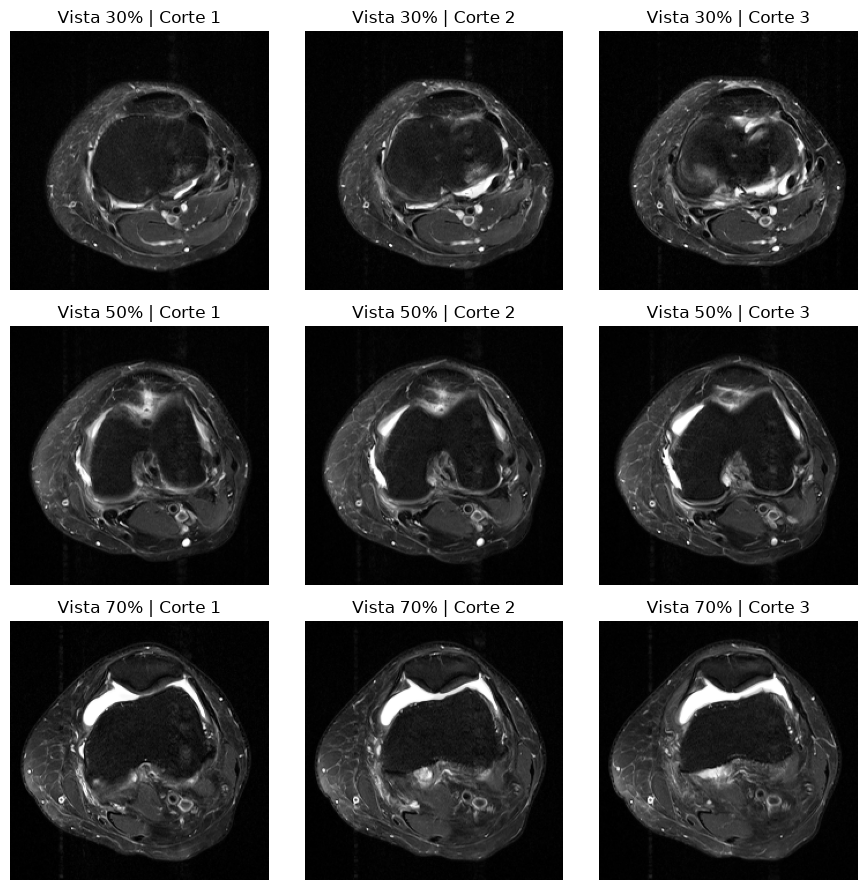

In [50]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3,3,figsize=(9, 9))

posiciones = [
    "30%",
    "50%",
    "70%"
]

for vista in range(3):

    for corte in range(3):

        axes[vista, corte].imshow(
            tensor_prueba[
                vista,
                corte
            ],
            cmap="gray"
        )

        axes[vista, corte].axis(
            "off"
        )

        axes[vista, corte].set_title(
            f"Vista {posiciones[vista]} | "
            f"Corte {corte + 1}"
        )

plt.tight_layout()
plt.show()

### Generación del dataset axial 2.5D completo

Una vez validado visualmente el preprocesamiento sobre una serie axial,
se aplica el mismo procedimiento a los 546 estudios seleccionados.

La posición de cada tensor se mantiene alineada con el manifest mediante
`ImageIndex`, permitiendo utilizar exactamente los mismos splits y etiquetas
que en el experimento sagital.

In [51]:
from tqdm import tqdm

# ============================================================
# CONFIGURACIÓN
# False: reutilizar tensor original
# True: reconstruir las 546 resonancias desde DICOM
# ============================================================

RECONSTRUIR_TENSOR_AXIAL = False

N = len(manifest_axial)
errores = []

if RECONSTRUIR_TENSOR_AXIAL:

    print("🔄 MODO RECONSTRUCCIÓN AXIAL")

    images_axial = np.empty(
        (N, 3, 3, 224, 224),
        dtype=np.uint8
    )

    for i, row in tqdm(
        manifest_axial.iterrows(),
        total=N,
        desc="Procesando axial 2.5D"
    ):

        ruta = (
            TRAIN_SERIES_DIR
            / str(row["StudyInstanceUID"])
            / str(row["SeriesInstanceUID"])
        )

        try:
            tensor, _, _ = crear_2_5d(ruta)

            if tensor.shape != (3, 3, 224, 224):
                raise ValueError(
                    f"Shape inesperada: {tensor.shape}"
                )

            images_axial[i] = tensor

        except Exception as e:
            errores.append({
                "ImageIndex": i,
                "StudyInstanceUID": row["StudyInstanceUID"],
                "SeriesInstanceUID": row["SeriesInstanceUID"],
                "Error": str(e)
            })

    if errores:
        print(pd.DataFrame(errores).head())
        raise RuntimeError(
            f"Reconstrucción incompleta: {len(errores)} errores"
        )

    metadata_axial = (
        manifest_axial.reset_index(drop=True).copy()
    )

    metadata_axial.insert(
        0, "ImageIndex", np.arange(N)
    )

else:

    print("✅ MODO RECUPERACIÓN AXIAL")

    assert AXIAL_IMAGES_PATH.is_file()
    assert AXIAL_METADATA_PATH.is_file()

    images_axial = np.load(
        AXIAL_IMAGES_PATH,
        mmap_mode="r"
    )

    metadata_axial = pd.read_csv(
        AXIAL_METADATA_PATH,
        dtype={
            "StudyInstanceUID": str,
            "SeriesInstanceUID": str
        }
    )

# Validaciones comunes
assert images_axial.shape == (N, 3, 3, 224, 224)
assert images_axial.dtype == np.uint8
assert len(metadata_axial) == N

assert sorted(
    metadata_axial["ImageIndex"].astype(int).tolist()
) == list(range(N))

print("\nEstudios disponibles:", N)
print("Errores:", len(errores))
print("Shape:", images_axial.shape)
print("dtype:", images_axial.dtype)

✅ MODO RECUPERACIÓN AXIAL

Estudios disponibles: 546
Errores: 0
Shape: (546, 3, 3, 224, 224)
dtype: uint8


In [52]:
print("Rango global:",images_axial.min(),images_axial.max())
print("Tamaño en MiB:",round(images_axial.nbytes/ 1024**2,2))

estudios_constantes = []

for i in range(len(images_axial)):

    if (images_axial[i].min()==images_axial[i].max()):
        estudios_constantes.append(i)

print("Tensores constantes:",len(estudios_constantes))

Rango global: 0 255
Tamaño en MiB: 235.14
Tensores constantes: 0


In [53]:
# Guardar solamente si se reconstruyó el tensor axial

if RECONSTRUIR_TENSOR_AXIAL:

    CARPETA_AXIAL_RECONSTRUIDO = (
        OUTPUT_DIR / "reconstruccion_axial"
    )

    CARPETA_AXIAL_RECONSTRUIDO.mkdir(
        parents=True,
        exist_ok=True
    )

    AXIAL_NPY_PATH = (
        CARPETA_AXIAL_RECONSTRUIDO
        / "images_2_5d_axial_uint8.npy"
    )

    AXIAL_METADATA_VERIFICACION_PATH = (
        CARPETA_AXIAL_RECONSTRUIDO
        / "metadata_2_5d_axial.csv"
    )

    # Evitar sobrescribir reconstrucciones anteriores
    if (
        AXIAL_NPY_PATH.exists()
        or AXIAL_METADATA_VERIFICACION_PATH.exists()
    ):
        raise FileExistsError(
            "Ya existen archivos reconstruidos en esta carpeta."
        )

    np.save(AXIAL_NPY_PATH, images_axial)

    metadata_axial.to_csv(
        AXIAL_METADATA_VERIFICACION_PATH,
        index=False
    )

    print("✅ Tensor axial reconstruido y guardado")

else:

    AXIAL_NPY_PATH = AXIAL_IMAGES_PATH

    AXIAL_METADATA_VERIFICACION_PATH = AXIAL_METADATA_PATH

    print("✅ Se reutiliza el tensor axial existente")
    print("✅ No se generaron archivos nuevos")

print("Tensor:", AXIAL_NPY_PATH)
print("Metadata:", AXIAL_METADATA_VERIFICACION_PATH)

✅ Se reutiliza el tensor axial existente
✅ No se generaron archivos nuevos
Tensor: C:\Users\PC\Documents\RSNA_Knee\processed\images_2_5d_axial_uint8.npy
Metadata: C:\Users\PC\Documents\RSNA_Knee\processed\metadata_2_5d_axial.csv


In [54]:
# Validar el tensor y la metadata correspondientes

check = np.load(
    AXIAL_NPY_PATH,
    mmap_mode="r"
)

check_meta = pd.read_csv(
    AXIAL_METADATA_VERIFICACION_PATH,
    dtype={
        "StudyInstanceUID": str,
        "SeriesInstanceUID": str
    }
)

assert check.shape == (546, 3, 3, 224, 224)
assert check.dtype == np.uint8
assert len(check_meta) == 546

assert sorted(
    check_meta["ImageIndex"].astype(int).tolist()
) == list(range(546))

assert check_meta["StudyInstanceUID"].is_unique

assert check_meta["Split"].value_counts().to_dict() == {
    "train": 490,
    "validation": 39,
    "test": 17
}

print("✅ Tensor y metadata axial validados")
print("Shape:", check.shape)
print("Metadata:", check_meta.shape)
print("\nSplits:")
print(check_meta["Split"].value_counts())

✅ Tensor y metadata axial validados
Shape: (546, 3, 3, 224, 224)
Metadata: (546, 26)

Splits:
Split
train         490
validation     39
test           17
Name: count, dtype: int64


Sagital                           Axial
(546,3,3,224,224)               (546,3,3,224,224)
        │                               │
        └──────── mismos 546 ──────────┘
                        ↓
                 EfficientNet-B0
                        ↓
                  AUC GOLD DEV
                        ↓
                 Sagital vs Axial

## Ablación 2: entrenamiento controlado Sagital vs Axial

Para aislar el efecto del plano de MRI se compara el modelo EfficientNet-B0
utilizando exactamente los mismos estudios, etiquetas, función de pérdida
Focal, inicialización, semilla e hiperparámetros.

La única variable modificada es el plano de adquisición:

- Sagital
- Axial

In [55]:
# Validar las rutas locales definidas al inicio del notebook

for nombre, ruta in {
    "Imágenes axiales": AXIAL_IMAGES_PATH,
    "Metadata axial": AXIAL_METADATA_PATH,
    "Manifiesto axial": AXIAL_MANIFEST_PATH
}.items():

    assert ruta.is_file(), f"No existe: {ruta}"

    print(f"✅ {nombre}: {ruta}")

✅ Imágenes axiales: C:\Users\PC\Documents\RSNA_Knee\processed\images_2_5d_axial_uint8.npy
✅ Metadata axial: C:\Users\PC\Documents\RSNA_Knee\processed\metadata_2_5d_axial.csv
✅ Manifiesto axial: C:\Users\PC\Documents\RSNA_Knee\manifest\manifest_axial_final.csv


In [56]:
images_axial = np.load(
    AXIAL_IMAGES_PATH,
    mmap_mode="r"
)

metadata_axial = pd.read_csv(
    AXIAL_METADATA_PATH
)

print(
    "Axial images:",
    images_axial.shape,
    images_axial.dtype
)

print(
    "Metadata axial:",
    metadata_axial.shape
)

print("\nSplits:")
print(
    metadata_axial["Split"]
    .value_counts()
)

Axial images: (546, 3, 3, 224, 224) uint8
Metadata axial: (546, 26)

Splits:
Split
train         490
validation     39
test           17
Name: count, dtype: int64


### Verifica y alinea Sagital/Axial

In [57]:
# Verificación de índices del NPY axial
assert metadata_axial["ImageIndex"].nunique() == 546
assert metadata_axial["ImageIndex"].min() == 0
assert metadata_axial["ImageIndex"].max() == 545

# Orden sagital de referencia
orden_sagital = {
    uid: i
    for i, uid in enumerate(
        metadata["StudyInstanceUID"].astype(str)
    )
}

metadata_axial["OrdenSagital"] = (
    metadata_axial["StudyInstanceUID"]
    .astype(str)
    .map(orden_sagital)
)

assert metadata_axial["OrdenSagital"].notna().all()

metadata_axial = (
    metadata_axial
    .sort_values("OrdenSagital")
    .reset_index(drop=True)
)

assert (
    metadata_axial["StudyInstanceUID"]
    .astype(str)
    .tolist()
    ==
    metadata["StudyInstanceUID"]
    .astype(str)
    .tolist()
)

print("✓ Estudios Sagital/Axial alineados:", len(metadata_axial))

✓ Estudios Sagital/Axial alineados: 546


### Crea train y validation axial

In [58]:
train_axial_df = metadata_axial[
    metadata_axial["Split"] == "train"
].copy()

val_axial_df = metadata_axial[
    metadata_axial["Split"] == "validation"
].copy()

test_axial_df = metadata_axial[
    metadata_axial["Split"] == "test"
].copy()

print("Train:", len(train_axial_df))
print("GOLD DEV:", len(val_axial_df))
print("HOLDOUT bloqueado:", len(test_axial_df))

Train: 490
GOLD DEV: 39
HOLDOUT bloqueado: 17


In [59]:
train_axial_dataset = KneeDataset(
    train_axial_df,
    images_axial,
    LABELS
)

val_axial_dataset = KneeDataset(
    val_axial_df,
    images_axial,
    LABELS
)

val_axial_loader = DataLoader(
    val_axial_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Train axial:", len(train_axial_dataset))
print("Validation axial:", len(val_axial_dataset))

Train axial: 490
Validation axial: 39


In [60]:
print(device)

cpu


In [61]:
# ============================================================
# ABLACIÓN AXIAL + FOCAL: ENTRENAR O RECUPERAR
# ============================================================

# Verificar que GOLD DEV sea el mismo en ambos planos
assert len(val_axial_df) == len(val_df) == 39

assert (
    val_axial_df["StudyInstanceUID"].astype(str).tolist()
    == val_df["StudyInstanceUID"].astype(str).tolist()
)

assert np.array_equal(
    val_axial_df[LABELS].to_numpy(),
    val_df[LABELS].to_numpy()
)

print("✅ GOLD DEV axial y sagital coinciden")

if MODO_ABLACION == "entrenar":

    # Mantener el entrenamiento original
    resultado_axial_focal = ejecutar_experimento(
        nombre="ablacion_axial_focal",
        loss_type="focal",
        estado_inicial=estado_inicial,
        device=device,
        train_dataset=train_axial_dataset,
        val_loader=val_axial_loader,
        pos_weight=pos_weight,
        seed=SEED_ABLACION,
        max_epochs=20,
        patience=4
    )

elif MODO_ABLACION == "recuperar":

    # Comprobar que existe el checkpoint histórico
    assert AXIAL_CHECKPOINT.is_file(), (
        f"No existe el checkpoint: {AXIAL_CHECKPOINT}"
    )

    # Reconstruir la misma arquitectura
    modelo_axial_focal = EfficientNet2_5D(
        num_classes=NUM_CLASSES,
        usar_imagenet=False
    ).to(device)

    # Cargar los pesos entrenados en Kaggle
    modelo_axial_focal.load_state_dict(
        torch.load(
            AXIAL_CHECKPOINT,
            map_location=device,
            weights_only=True
        )
    )

    modelo_axial_focal.eval()

    # Evaluar únicamente los 39 estudios GOLD DEV
    auc_axial_local, aucs_axial_local = evaluar_auc(
        modelo_axial_focal,
        val_axial_loader,
        device,
        LABELS
    )

    # La época 13 está documentada en el
    # entrenamiento histórico de este notebook.
    mejor_epoca_historica = 13

    # No inventar un historial de entrenamiento nuevo
    historial_axial = pd.DataFrame(
        columns=[
            "epoch",
            "train_loss",
            "val_auc_macro"
        ]
    )

    resultado_axial_focal = {
        "nombre": "ablacion_axial_focal",
        "best_auc": float(auc_axial_local),
        "best_epoch": mejor_epoca_historica,
        "best_path": AXIAL_CHECKPOINT,
        "historial": historial_axial
    }

    print("✅ Modelo Axial + Focal recuperado")
    print("Checkpoint:", AXIAL_CHECKPOINT)
    print("AUC histórico esperado: 0.7061")

else:

    raise ValueError(
        "MODO_ABLACION debe ser 'entrenar' o 'recuperar'"
    )

print("\nMejor época Axial Focal:",
      resultado_axial_focal["best_epoch"])

print("AUC Axial Focal GOLD DEV:",
      round(resultado_axial_focal["best_auc"], 4))

✅ GOLD DEV axial y sagital coinciden
✅ Modelo Axial + Focal recuperado
Checkpoint: C:\Users\PC\Documents\RSNA_Knee\checkpoint\best_ablacion_axial_focal.pth
AUC histórico esperado: 0.7061

Mejor época Axial Focal: 13
AUC Axial Focal GOLD DEV: 0.7061


In [62]:
# ============================================================
# COMPARACIÓN SAGITAL VS AXIAL - FOCAL LOSS
# ============================================================

comparacion_planos = pd.DataFrame({
    "Plano": [
        "Sagital",
        "Axial"
    ],
    "Loss": [
        "Focal",
        "Focal"
    ],
    "Macro_AUC_DEV": [
        resultado_focal["best_auc"],
        resultado_axial_focal["best_auc"]
    ],
    "Best_Epoch": [
        resultado_focal["best_epoch"],
        resultado_axial_focal["best_epoch"]
    ]
})

comparacion_planos["Delta_vs_Sagital"] = (
    comparacion_planos["Macro_AUC_DEV"]
    - comparacion_planos.loc[
        comparacion_planos["Plano"] == "Sagital",
        "Macro_AUC_DEV"
    ].iloc[0]
)

display(comparacion_planos)

# Guardar resultados en Windows
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

COMPARACION_PLANOS_PATH = (
    OUTPUT_DIR / "comparacion_sagital_vs_axial.csv"
)

comparacion_planos.to_csv(
    COMPARACION_PLANOS_PATH,
    index=False
)

print("✅ Comparación guardada correctamente")
print("Ruta:", COMPARACION_PLANOS_PATH)

,Plano,Loss,Macro_AUC_DEV,Best_Epoch,Delta_vs_Sagital
0,Sagital,Focal,0.754068,NaN,0.000000
1,Axial,Focal,0.706067,13.0,-0.048001


✅ Comparación guardada correctamente
Ruta: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\comparacion_sagital_vs_axial.csv


### Resultado de la ablación por plano

Manteniendo constante la arquitectura EfficientNet-B0, la inicialización,
los estudios utilizados, la función de pérdida Focal y los hiperparámetros,
el plano sagital obtuvo un AUC-ROC macro de 0.7541 sobre GOLD DEV, mientras
que el plano axial alcanzó 0.7061.

La diferencia absoluta fue de 0.0480 a favor del plano sagital. Por este
motivo, el plano sagital se conserva como configuración principal para las
etapas posteriores del experimento.

En el modelo axial se observó además una reducción continua de la pérdida
de entrenamiento después de la época 13 sin mejora equivalente del AUC de
validación, compatible con sobreajuste. El mecanismo de early stopping
detuvo el entrenamiento en la época 17 y conservó el checkpoint de la
época 13.

### Comparación del rendimiento según plano de MRI

Se compara el AUC-ROC macro obtenido sobre el conjunto GOLD DEV manteniendo
constantes la arquitectura EfficientNet-B0, la función de pérdida Focal,
la inicialización, los estudios utilizados y los hiperparámetros.

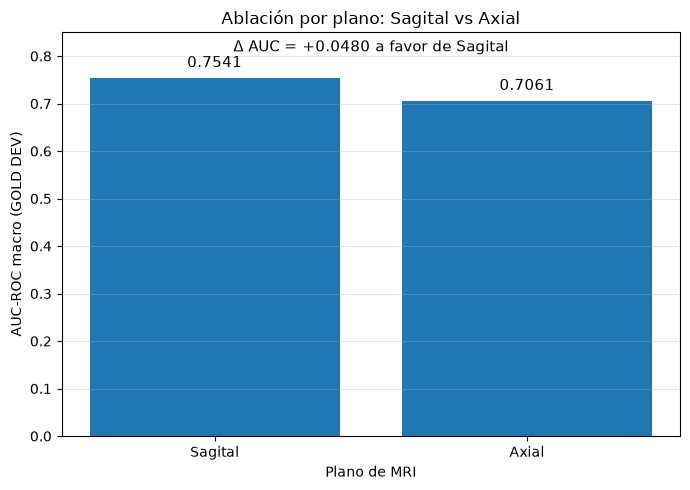

✅ Gráfico guardado correctamente
Ruta: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\ablacion_sagital_vs_axial.png


In [63]:
import matplotlib.pyplot as plt

# ============================================================
# GRÁFICO: ABLACIÓN SAGITAL VS AXIAL
# ============================================================

planos = ["Sagital", "Axial"]

# Utilizar los AUC calculados, no valores escritos manualmente
auc_planos = [
    resultado_focal["best_auc"],
    resultado_axial_focal["best_auc"]
]

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    planos,
    auc_planos
)

ax.set_ylim(0, 0.85)

ax.set_ylabel("AUC-ROC macro (GOLD DEV)")
ax.set_xlabel("Plano de MRI")
ax.set_title("Ablación por plano: Sagital vs Axial")

# Mostrar AUC encima de cada barra
for bar, valor in zip(bars, auc_planos):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        valor + 0.015,
        f"{valor:.4f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

# Diferencia entre planos
delta = auc_planos[0] - auc_planos[1]

ax.text(
    0.5,
    0.81,
    f"Δ AUC = +{delta:.4f} a favor de Sagital",
    ha="center",
    fontsize=11
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

# Guardar gráfico en Windows
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

GRAFICO_PLANOS_PATH = (
    OUTPUT_DIR / "ablacion_sagital_vs_axial.png"
)

plt.savefig(
    GRAFICO_PLANOS_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Gráfico guardado correctamente")
print("Ruta:", GRAFICO_PLANOS_PATH)

### Evolución del entrenamiento del modelo axial

La pérdida de entrenamiento disminuye de forma sostenida durante las épocas.
Sin embargo, el AUC-ROC sobre GOLD DEV alcanza su máximo en la época 13 y
posteriormente disminuye, lo que sugiere el inicio de sobreajuste.

Por este motivo se utiliza early stopping y se conserva el checkpoint
correspondiente a la mejor época de validación.

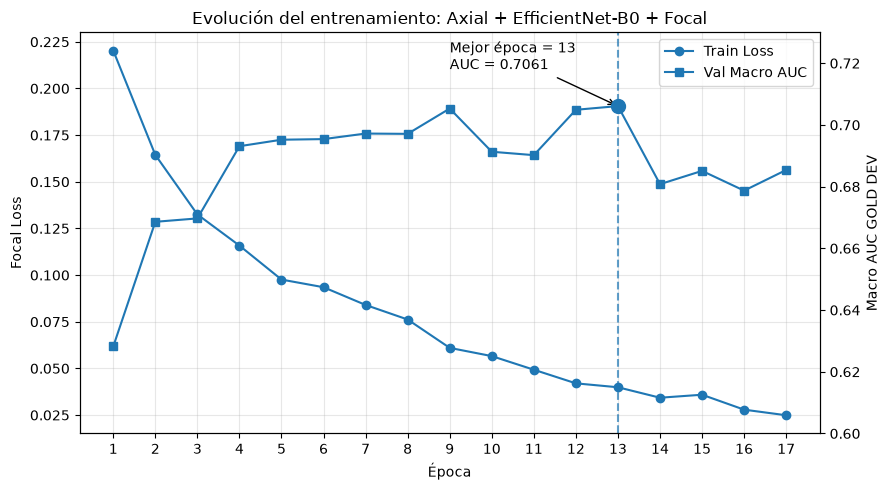

✅ Gráfico histórico axial guardado
Ruta: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\entrenamiento_axial_focal.png


In [64]:
import matplotlib.pyplot as plt

epochs = list(range(1, 18))

train_loss = [
    0.2203,
    0.1644,
    0.1325,
    0.1158,
    0.0976,
    0.0935,
    0.0840,
    0.0762,
    0.0610,
    0.0566,
    0.0493,
    0.0420,
    0.0399,
    0.0343,
    0.0359,
    0.0279,
    0.0249
]

val_auc = [
    0.6282,
    0.6686,
    0.6697,
    0.6931,
    0.6952,
    0.6954,
    0.6972,
    0.6971,
    0.7053,
    0.6913,
    0.6902,
    0.7049,
    0.7061,
    0.6808,
    0.6851,
    0.6787,
    0.6854
]

fig, ax1 = plt.subplots(
    figsize=(9, 5)
)

# Loss
line1 = ax1.plot(
    epochs,
    train_loss,
    marker="o",
    label="Train Loss"
)

ax1.set_xlabel(
    "Época"
)

ax1.set_ylabel(
    "Focal Loss"
)

ax1.set_xticks(
    epochs
)

ax1.grid(
    alpha=0.3
)

# Segundo eje para AUC
ax2 = ax1.twinx()

line2 = ax2.plot(
    epochs,
    val_auc,
    marker="s",
    label="Val Macro AUC"
)

ax2.set_ylabel(
    "Macro AUC GOLD DEV"
)

ax2.set_ylim(
    0.60,
    0.73
)

# Mejor época
best_epoch = 13
best_auc = 0.7061

ax1.axvline(
    x=best_epoch,
    linestyle="--",
    alpha=0.7
)

ax2.scatter(
    best_epoch,
    best_auc,
    s=100,
    zorder=5
)

ax2.annotate(
    f"Mejor época = {best_epoch}\nAUC = {best_auc:.4f}",
    xy=(
        best_epoch,
        best_auc
    ),
    xytext=(
        best_epoch - 4,
        best_auc + 0.012
    ),
    arrowprops={
        "arrowstyle": "->"
    }
)

plt.title(
    "Evolución del entrenamiento: Axial + EfficientNet-B0 + Focal"
)

# Leyenda combinada
lines = (
    line1
    + line2
)

labels = [
    line.get_label()
    for line in lines
]

ax1.legend(
    lines,
    labels,
    loc="upper right"
)

plt.tight_layout()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RUTA_GRAFICO_AXIAL = (
    OUTPUT_DIR / "entrenamiento_axial_focal.png"
)

plt.savefig(
    RUTA_GRAFICO_AXIAL,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Gráfico histórico axial guardado")
print("Ruta:", RUTA_GRAFICO_AXIAL)

### Comparación de rendimiento: BCE vs Focal Loss

Se compara el mejor AUC-ROC macro obtenido sobre GOLD DEV bajo condiciones
controladas. Ambos experimentos utilizan la misma arquitectura EfficientNet-B0,
la misma inicialización, los mismos datos, semilla, optimizador e
hiperparámetros. La única variable modificada es la función de pérdida.

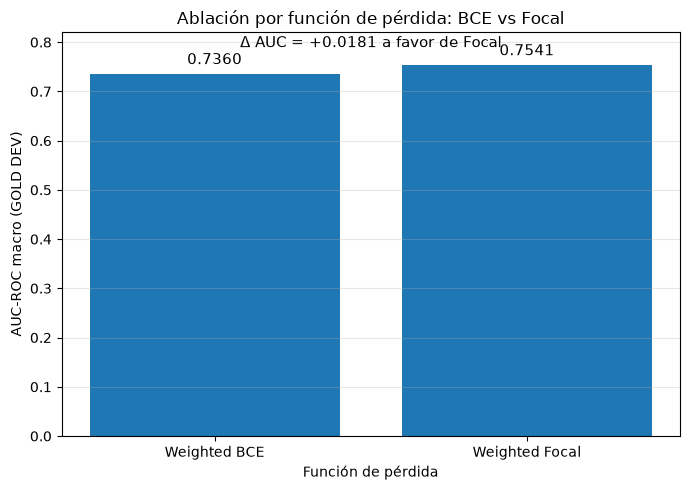

✅ Gráfico BCE vs. Focal guardado
Ruta: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\ablacion_bce_vs_focal_auc.png


In [65]:
import matplotlib.pyplot as plt

auc_bce_best = resultado_bce["best_auc"]
auc_focal_best = resultado_focal["best_auc"]

loss_names = [
    "Weighted BCE",
    "Weighted Focal"
]

auc_values = [
    auc_bce_best,
    auc_focal_best
]

plt.figure(
    figsize=(7, 5)
)

bars = plt.bar(
    loss_names,
    auc_values
)

plt.ylim(
    0,
    0.82
)

plt.ylabel(
    "AUC-ROC macro (GOLD DEV)"
)

plt.xlabel(
    "Función de pérdida"
)

plt.title(
    "Ablación por función de pérdida: BCE vs Focal"
)

for bar, valor in zip(
    bars,
    auc_values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        valor + 0.012,
        f"{valor:.4f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

delta = (
    auc_focal_best
    - auc_bce_best
)

plt.text(
    0.5,
    0.79,
    f"Δ AUC = +{delta:.4f} a favor de Focal",
    ha="center",
    fontsize=11
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RUTA_GRAFICO_LOSS = (
    OUTPUT_DIR / "ablacion_bce_vs_focal_auc.png"
)

plt.savefig(
    RUTA_GRAFICO_LOSS,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Gráfico BCE vs. Focal guardado")
print("Ruta:", RUTA_GRAFICO_LOSS)

### Evolución del AUC de validación: BCE vs Focal Loss

Las curvas muestran el AUC-ROC macro obtenido sobre GOLD DEV durante el
entrenamiento. BCE alcanzó su mejor resultado en la época 7, mientras que
Focal Loss continuó mejorando hasta alcanzar su máximo en la época 17.

In [66]:
# ============================================================
# EVOLUCIÓN DEL AUC: BCE VS FOCAL
# ============================================================

hist_bce = pd.DataFrame(
    resultado_bce["historial"]
)

hist_focal = pd.DataFrame(
    resultado_focal["historial"]
)

if hist_bce.empty or hist_focal.empty:

    print("ℹ️ No se dispone de ambos historiales completos.")
    print("Se conservaron los AUC recuperados de los checkpoints.")
    print("No se genera una curva de entrenamiento artificial.")

else:

    columnas = {"epoch", "val_auc_macro"}

    assert columnas.issubset(hist_bce.columns)
    assert columnas.issubset(hist_focal.columns)

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(
        hist_bce["epoch"],
        hist_bce["val_auc_macro"],
        marker="o",
        label="Weighted BCE"
    )

    ax.plot(
        hist_focal["epoch"],
        hist_focal["val_auc_macro"],
        marker="s",
        label="Weighted Focal"
    )

    ax.set_xlabel("Época")
    ax.set_ylabel("AUC-ROC macro (GOLD DEV)")
    ax.set_title(
        "Evolución de validación: BCE vs. Focal"
    )

    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    RUTA_EVOLUCION_LOSS = (
        OUTPUT_DIR / "evolucion_auc_bce_vs_focal.png"
    )

    plt.savefig(
        RUTA_EVOLUCION_LOSS,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("✅ Evolución BCE vs. Focal guardada")

ℹ️ No se dispone de ambos historiales completos.
Se conservaron los AUC recuperados de los checkpoints.
No se genera una curva de entrenamiento artificial.


### Cargar el mejor modelo Focal sagital

In [67]:
# ============================================================
# CARGAR EL MEJOR MODELO FOCAL SAGITAL
# ============================================================

# Verificar que exista el checkpoint
assert FOCAL_CHECKPOINT.is_file(), (
    f"No existe el checkpoint: {FOCAL_CHECKPOINT}"
)

# Reconstruir la arquitectura original
modelo_final = EfficientNet2_5D(
    num_classes=len(LABELS),
    usar_imagenet=False
).to(device)

# Recuperar los pesos entrenados en Kaggle
modelo_final.load_state_dict(
    torch.load(
        FOCAL_CHECKPOINT,
        map_location=device,
        weights_only=True
    )
)

# Poner el modelo en modo evaluación
modelo_final.eval()

print("✅ Mejor modelo Focal sagital cargado")
print("Checkpoint:", FOCAL_CHECKPOINT)
print("Dispositivo:", device)

✅ Mejor modelo Focal sagital cargado
Checkpoint: C:\Users\PC\Documents\RSNA_Knee\checkpoint\best_ablacion_focal.pth
Dispositivo: cpu


### Obtener probabilidades sobre GOLD DEV

In [68]:
@torch.no_grad()
def obtener_predicciones(
    model,
    loader,
    device
):
    probs_all = []
    targets_all = []

    model.eval()

    for x, y in loader:

        x = x.to(
            device,
            non_blocking=True
        )

        logits = model(x)

        probs = torch.sigmoid(
            logits
        )

        probs_all.append(
            probs.cpu().numpy()
        )

        targets_all.append(
            y.numpy()
        )

    return (
        np.concatenate(
            probs_all,
            axis=0
        ),
        np.concatenate(
            targets_all,
            axis=0
        )
    )


probs_dev, y_dev = obtener_predicciones(
    modelo_final,
    val_loader,
    device
)

print(
    "Probabilidades:",
    probs_dev.shape
)

print(
    "Targets:",
    y_dev.shape
)

Probabilidades: (39, 12)
Targets: (39, 12)


### Buscar el mejor umbral global

In [69]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(
    0.05,
    0.96,
    0.01
)

resultados_threshold = []

for t in thresholds:

    pred = (
        probs_dev >= t
    ).astype(int)

    precision = precision_score(
        y_dev,
        pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_dev,
        pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_dev,
        pred,
        average="macro",
        zero_division=0
    )

    resultados_threshold.append(
        {
            "threshold": t,
            "precision_macro": precision,
            "recall_macro": recall,
            "f1_macro": f1
        }
    )

df_threshold = pd.DataFrame(
    resultados_threshold
)

display(
    df_threshold.sort_values(
        "f1_macro",
        ascending=False
    ).head(10)
)

,threshold,precision_macro,recall_macro,f1_macro
49,0.54,0.538105,0.789625,0.629338
48,0.53,0.535964,0.789625,0.627876
51,0.56,0.541359,0.772997,0.627255
52,0.57,0.547972,0.760176,0.627164
47,0.52,0.531887,0.796035,0.626513
50,0.55,0.537903,0.776083,0.625795
58,0.63,0.565748,0.720582,0.625608
53,0.58,0.545200,0.750066,0.622141
57,0.62,0.556726,0.720582,0.619119
46,0.51,0.519342,0.802980,0.618736


In [70]:
mejor_fila = df_threshold.loc[
    df_threshold[
        "f1_macro"
    ].idxmax()
]

UMBRAL_FINAL = float(
    mejor_fila[
        "threshold"
    ]
)

print("Umbral óptimo:",round(UMBRAL_FINAL,2))
print("Precision macro:",round(mejor_fila["precision_macro"],4))
print("Recall macro:",round(mejor_fila["recall_macro"],4))
print("F1 macro:",round(mejor_fila["f1_macro"],4))

Umbral óptimo: 0.54
Precision macro: 0.5381
Recall macro: 0.7896
F1 macro: 0.6293


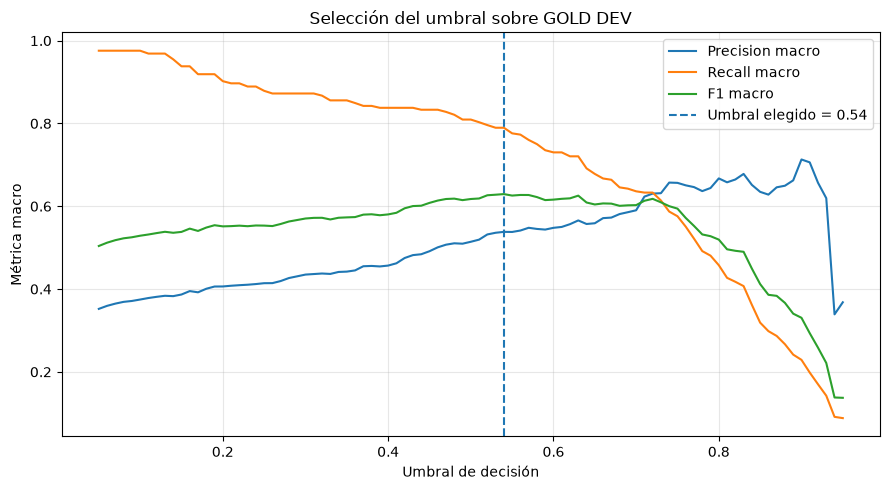

✅ Gráfico de selección del umbral guardado
Ruta: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\seleccion_umbral_gold_dev.png


In [71]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["precision_macro"],
    label="Precision macro"
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["recall_macro"],
    label="Recall macro"
)

plt.plot(
    df_threshold["threshold"],
    df_threshold["f1_macro"],
    label="F1 macro"
)

plt.axvline(
    UMBRAL_FINAL,
    linestyle="--",
    label=f"Umbral elegido = {UMBRAL_FINAL:.2f}"
)

plt.xlabel("Umbral de decisión")

plt.ylabel("Métrica macro")

plt.title("Selección del umbral sobre GOLD DEV")

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

# Guardar gráfico en Windows
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RUTA_GRAFICO_UMBRAL = (
    OUTPUT_DIR / "seleccion_umbral_gold_dev.png"
)

plt.savefig(
    RUTA_GRAFICO_UMBRAL,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Gráfico de selección del umbral guardado")
print("Ruta:", RUTA_GRAFICO_UMBRAL)

## Evaluación por hallazgo sobre GOLD DEV

Una vez seleccionado el umbral global de 0.54 utilizando únicamente el
conjunto GOLD DEV, se calculan las métricas individuales para cada uno de
los doce hallazgos.

Se reportan AUC-ROC, precisión, recall y F1, junto con el número de casos
positivos y negativos presentes en el conjunto de validación.

In [72]:
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

pred_dev = (
    probs_dev >= UMBRAL_FINAL
).astype(int)

metricas_labels = []

for j, label in enumerate(LABELS):

    y_true = y_dev[:, j].astype(int)
    y_pred = pred_dev[:, j]
    y_prob = probs_dev[:, j]

    positivos = int(
        (y_true == 1).sum()
    )

    negativos = int(
        (y_true == 0).sum()
    )

    # AUC requiere ambas clases
    if len(np.unique(y_true)) == 2:

        auc = roc_auc_score(
            y_true,
            y_prob
        )

    else:

        auc = np.nan

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    metricas_labels.append(
        {
            "Hallazgo": label,
            "Positivos": positivos,
            "Negativos": negativos,
            "AUC": auc,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        }
    )

metricas_por_label = pd.DataFrame(
    metricas_labels
)

display(
    metricas_por_label.round(4)
)

,Hallazgo,Positivos,Negativos,AUC,Precision,Recall,F1
0,ACL,16,23,0.7527,0.5909,0.8125,0.6842
1,MCL,6,33,0.5404,0.2727,0.5000,0.3529
2,Medial Meniscus,17,22,0.8021,0.5152,1.0000,0.6800
3,Lateral Meniscus,16,23,0.8043,0.5357,0.9375,0.6818
4,Medial OA,10,29,0.8552,0.6000,0.9000,0.7200
5,Lateral OA,8,31,0.7258,0.5556,0.6250,0.5882
6,PF OA,13,26,0.8521,0.7500,0.6923,0.7200
7,Effusion,27,12,0.8395,0.8333,0.9259,0.8772
8,Synovitis,18,21,0.7460,0.6087,0.7778,0.6829
9,Baker's,8,31,0.8226,0.3684,0.8750,0.5185


In [73]:
resumen_macro = pd.DataFrame(
    {
        "Métrica": [
            "AUC macro",
            "Precision macro",
            "Recall macro",
            "F1 macro"
        ],

        "Valor": [
            metricas_por_label["AUC"].mean(),
            metricas_por_label["Precision"].mean(),
            metricas_por_label["Recall"].mean(),
            metricas_por_label["F1"].mean()
        ]
    }
)

display(resumen_macro.round(4))

,Métrica,Valor
0,AUC macro,0.7541
1,Precision macro,0.5381
2,Recall macro,0.7896
3,F1 macro,0.6293


### Guardemos la tabla

In [74]:
# ============================================================
# GUARDAR MÉTRICAS DEL MODELO FINAL - GOLD DEV
# ============================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RUTA_METRICAS_LABEL = (
    OUTPUT_DIR / "metricas_por_label_modelo_final_dev.csv"
)

RUTA_RESUMEN_MACRO = (
    OUTPUT_DIR / "metricas_macro_modelo_final_dev.csv"
)

metricas_por_label.to_csv(
    RUTA_METRICAS_LABEL,
    index=False
)

resumen_macro.to_csv(
    RUTA_RESUMEN_MACRO,
    index=False
)

assert RUTA_METRICAS_LABEL.is_file()
assert RUTA_RESUMEN_MACRO.is_file()

print("✅ Métricas por patología guardadas")
print("Ruta:", RUTA_METRICAS_LABEL)
print("✅ Resumen macro guardado")
print("Ruta:", RUTA_RESUMEN_MACRO)

✅ Métricas por patología guardadas
Ruta: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\metricas_por_label_modelo_final_dev.csv
✅ Resumen macro guardado
Ruta: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\metricas_macro_modelo_final_dev.csv


✅ Gráfico guardado: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\rendimiento_por_hallazgo_dev.png


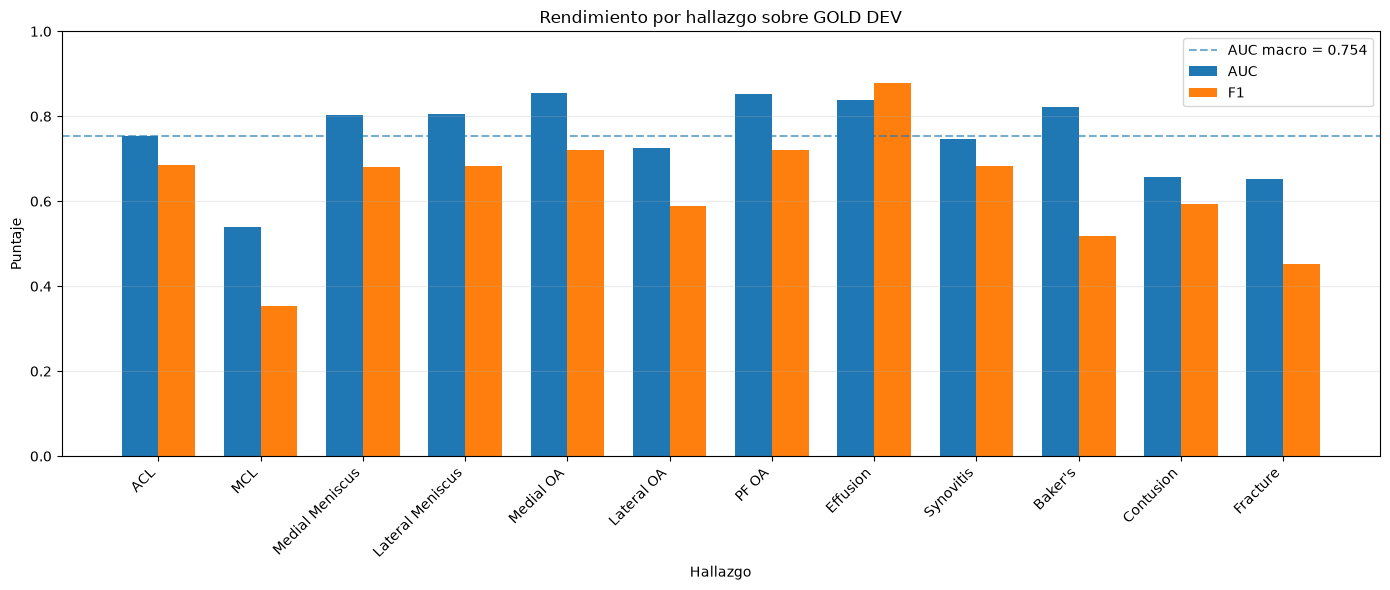

In [75]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(
    len(metricas_por_label)
)

width = 0.36

plt.figure(
    figsize=(14, 6)
)

plt.bar(
    x - width / 2,
    metricas_por_label["AUC"],
    width,
    label="AUC"
)

plt.bar(
    x + width / 2,
    metricas_por_label["F1"],
    width,
    label="F1"
)

plt.xticks(
    x,
    metricas_por_label["Hallazgo"],
    rotation=45,
    ha="right"
)

plt.ylim(0,1)

plt.ylabel("Puntaje")

plt.xlabel("Hallazgo")

plt.title("Rendimiento por hallazgo sobre GOLD DEV")

plt.axhline(
    metricas_por_label["AUC"].mean(),
    linestyle="--",
    alpha=0.6,
    label=(
        f"AUC macro = "
        f"{metricas_por_label['AUC'].mean():.3f}"
    )
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.legend()

plt.tight_layout()

RUTA_RENDIMIENTO_LABEL = (
    OUTPUT_DIR / "rendimiento_por_hallazgo_dev.png"
)

plt.savefig(
    RUTA_RENDIMIENTO_LABEL,
    dpi=300,
    bbox_inches="tight"
)

print("✅ Gráfico guardado:", RUTA_RENDIMIENTO_LABEL)

## Grad-CAM del modelo final

Se utiliza Grad-CAM sobre la última capa convolucional de EfficientNet-B0
para analizar qué regiones de la MRI contribuyen a la predicción de distintos
hallazgos.

Se seleccionan tres hallazgos con buen rendimiento en GOLD DEV y con regiones
anatómicas diferentes:

- Medial Meniscus
- Effusion
- Medial OA

Para cada hallazgo se selecciona de forma reproducible el caso positivo de
GOLD DEV con mayor probabilidad predicha.

In [76]:
import torch.nn.functional as F

class GradCAM25D:

    def __init__(self,model,target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_handle = (
            target_layer.register_forward_hook(
                self._forward_hook
            )
        )

        self.backward_handle = (
            target_layer.register_full_backward_hook(
                self._backward_hook
            )
        )


    def _forward_hook(self,module,input,output):

        self.activations = output.detach()


    def _backward_hook(self,module,grad_input,grad_output):

        self.gradients = grad_output[0].detach()


    def generate(self,x,class_idx):

        self.model.zero_grad()

        logits = self.model(x)

        score = logits[
            0,
            class_idx
        ]

        score.backward()

        activations = self.activations
        gradients = self.gradients

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights
            * activations
        ).sum(
            dim=1
        )

        cam = torch.relu(cam)

        # [3, 7, 7] aproximadamente
        cam = cam.unsqueeze(1)

        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam.squeeze(1)

        # Normalización independiente por vista
        cams_normalized = []

        for view_cam in cam:

            cmin = view_cam.min()
            cmax = view_cam.max()

            view_cam = (
                view_cam - cmin
            ) / (
                cmax - cmin + 1e-8
            )

            cams_normalized.append(
                view_cam
            )

        cam = torch.stack(
            cams_normalized
        )

        return (
            cam.cpu().numpy(),
            logits.detach().cpu().numpy()
        )


    def remove_hooks(self):

        self.forward_handle.remove()
        self.backward_handle.remove()

### Seleccionar automáticamente los 3 casos

In [77]:
HALLAZGOS_GRADCAM = [
    "Medial Meniscus",
    "Effusion",
    "Medial OA"
]

casos_gradcam = {}

for hallazgo in HALLAZGOS_GRADCAM:

    class_idx = LABELS.index(
        hallazgo
    )

    positivos = np.where(
        y_dev[:, class_idx] == 1
    )[0]

    mejor_idx = positivos[
        np.argmax(
            probs_dev[
                positivos,
                class_idx
            ]
        )
    ]

    casos_gradcam[
        hallazgo
    ] = int(mejor_idx)

    print(hallazgo,"| índice DEV:",mejor_idx,"| prob:",round(probs_dev[mejor_idx,class_idx],4))

Medial Meniscus | índice DEV: 35 | prob: 0.9637
Effusion | índice DEV: 29 | prob: 0.994
Medial OA | índice DEV: 8 | prob: 0.9379


### Generar los Mapas

In [78]:
gradcam = GradCAM25D(
    modelo_final,
    modelo_final.backbone.features[-1]
)

resultados_gradcam = {}

for hallazgo, sample_idx in casos_gradcam.items():

    class_idx = LABELS.index(
        hallazgo
    )

    x, y = val_dataset[
        sample_idx
    ]

    x_batch = (
        x.unsqueeze(0)
        .to(device)
    )

    cams, logits = gradcam.generate(
        x_batch,
        class_idx
    )

    prob = torch.sigmoid(
        torch.tensor(
            logits[
                0,
                class_idx
            ]
        )
    ).item()

    resultados_gradcam[
        hallazgo
    ] = {
        "sample_idx": sample_idx,
        "x": x.numpy(),
        "cams": cams,
        "prob": prob
    }

gradcam.remove_hooks()

In [79]:
for hallazgo, resultado in resultados_gradcam.items():
    print(
        hallazgo,
        "| Imagen:", resultado["x"].shape,
        "| Grad-CAM:", resultado["cams"].shape,
        "| Min:", resultado["cams"].min(),
        "| Max:", resultado["cams"].max(),
        "| NaN:", np.isnan(resultado["cams"]).sum()
    )

Medial Meniscus | Imagen: (3, 3, 224, 224) | Grad-CAM: (3, 224, 224) | Min: 0.0 | Max: 0.99999994 | NaN: 0
Effusion | Imagen: (3, 3, 224, 224) | Grad-CAM: (3, 224, 224) | Min: 0.0 | Max: 1.0 | NaN: 0
Medial OA | Imagen: (3, 3, 224, 224) | Grad-CAM: (3, 224, 224) | Min: 0.0 | Max: 0.99999994 | NaN: 0


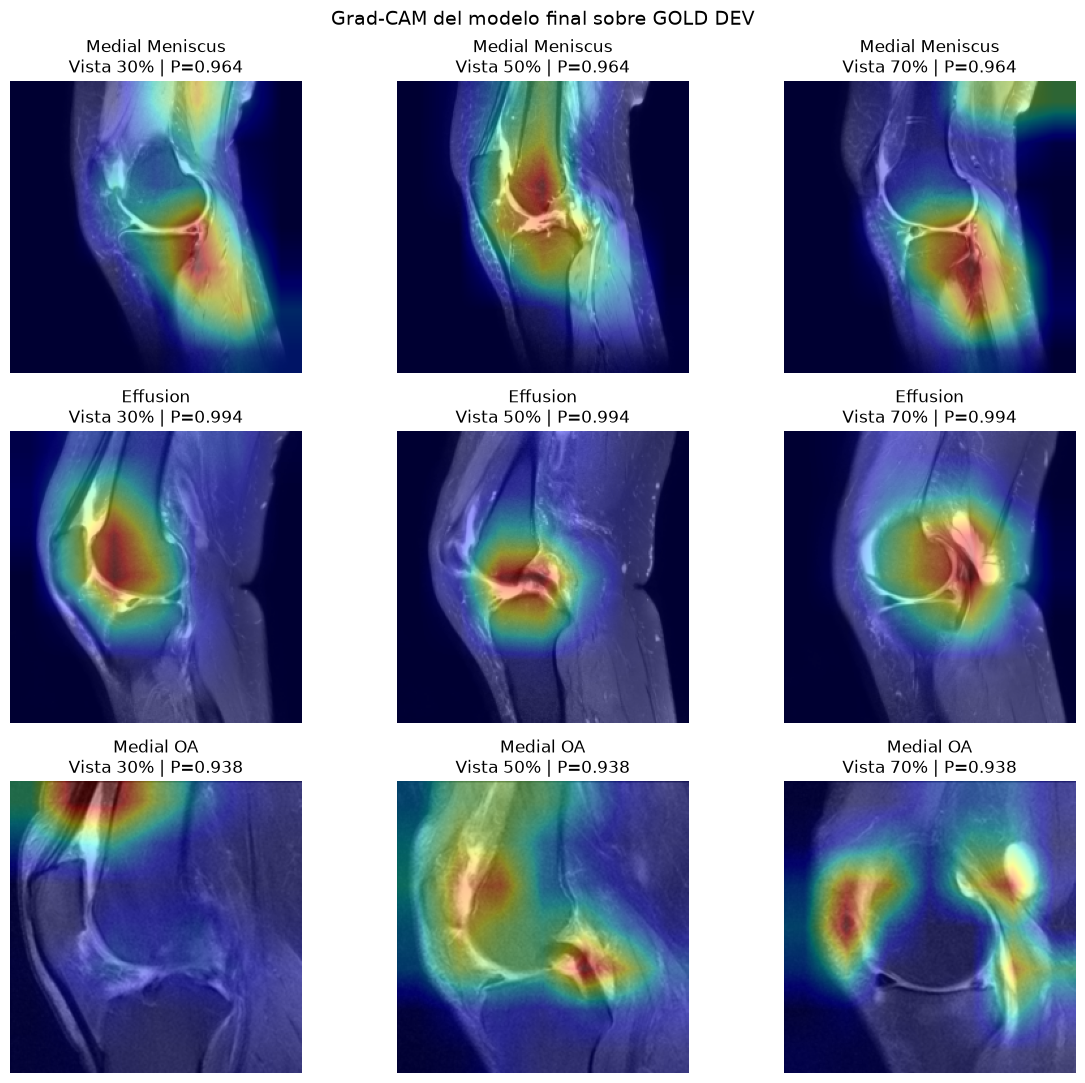

✅ Grad-CAM guardado: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\gradcam_tres_hallazgos.png


In [80]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 11)
)

vistas = [
    "30%",
    "50%",
    "70%"
]

for fila, hallazgo in enumerate(
    HALLAZGOS_GRADCAM
):

    resultado = resultados_gradcam[
        hallazgo
    ]

    x = resultado["x"]
    cams = resultado["cams"]
    prob = resultado["prob"]

    for vista in range(3):

        # Canal central de cada vista 2.5D
        imagen = x[
            vista,
            1
        ]

        axes[
            fila,
            vista
        ].imshow(
            imagen,
            cmap="gray"
        )

        axes[
            fila,
            vista
        ].imshow(
            cams[vista],
            cmap="jet",
            alpha=0.40
        )

        axes[
            fila,
            vista
        ].axis(
            "off"
        )

        axes[
            fila,
            vista
        ].set_title(
            f"{hallazgo}\n"
            f"Vista {vistas[vista]} | "
            f"P={prob:.3f}"
        )

plt.suptitle(
    "Grad-CAM del modelo final sobre GOLD DEV",
    fontsize=14
)

plt.tight_layout()

RUTA_GRADCAM = (
    OUTPUT_DIR / "gradcam_tres_hallazgos.png"
)

plt.savefig(
    RUTA_GRADCAM,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Grad-CAM guardado:", RUTA_GRADCAM)

### Interpretación de Grad-CAM

Los mapas Grad-CAM muestran que el modelo utiliza principalmente regiones
anatómicas relacionadas con la articulación de la rodilla para realizar sus
predicciones.

Para **Medial Meniscus**, las activaciones se concentran predominantemente
alrededor de la línea articular femorotibial y la región meniscal, especialmente
en las vistas correspondientes al 30 % y 70 % de la profundidad, lo cual es
anatómicamente plausible.

Para **Effusion**, se observa atención alrededor del espacio articular y regiones
periarticulares compatibles con áreas donde puede acumularse líquido. La
distribución de la atención varía entre las tres vistas, indicando que el modelo
combina información procedente de diferentes cortes.

Para **Medial OA**, las vistas centrales muestran activaciones sobre regiones
articulares y subcondrales compatibles con cambios degenerativos. Sin embargo,
también se observa activación periférica en una de las vistas, lo que sugiere que
el modelo puede utilizar características no directamente relacionadas con la
lesión.

Estos resultados deben interpretarse de forma cualitativa. Grad-CAM indica qué
regiones influyen en la predicción, pero no constituye una segmentación de la
lesión ni demuestra que el modelo utilice exclusivamente características
anatómicamente correctas. Además, en la representación 2.5D los tres canales de
entrada corresponden a cortes contiguos de MRI, mientras que EfficientNet-B0 fue
preentrenada originalmente con canales RGB.

## Análisis del desbalance de clases

Las etiquetas de entrenamiento provienen de supervisión débil y pueden tomar
tres valores: positivo (1), negativo (0) y abstención (-1).

Por ello, la prevalencia de cada hallazgo se calcula únicamente sobre las
etiquetas resueltas. Además, se reporta la cobertura de etiquetado para mostrar
qué proporción de los 490 estudios dispone de una etiqueta débil utilizable
para cada hallazgo.

Como estrategia de mitigación del desbalance se utiliza ponderación positiva
(`pos_weight`) junto con Focal Loss, de modo que los ejemplos positivos raros
y los casos difíciles tengan mayor influencia durante el entrenamiento.

### Tabla de desbalance de las 12 clases

In [81]:
analisis_desbalance = []

for label in LABELS:

    valores = train_df[
        label
    ].values

    positivos = int((valores == 1).sum())

    negativos = int((valores == 0).sum())

    abstenciones = int((valores == -1).sum())

    resueltos = (positivos+ negativos)

    cobertura = (
        resueltos
        / len(valores)
    )

    prevalencia = (
        positivos / resueltos
        if resueltos > 0
        else np.nan
    )

    peso_positivo = (
        negativos / positivos
        if positivos > 0
        else np.nan
    )

    analisis_desbalance.append(
        {
            "Hallazgo": label,
            "Positivos": positivos,
            "Negativos": negativos,
            "Abstenciones": abstenciones,
            "Cobertura": cobertura,
            "Prevalencia_resuelta": prevalencia,
            "Pos_weight": peso_positivo
        }
    )

df_desbalance = pd.DataFrame(analisis_desbalance)

display(df_desbalance.round(4))

,Hallazgo,Positivos,Negativos,Abstenciones,Cobertura,Prevalencia_resuelta,Pos_weight
0,ACL,91,366,33,0.9327,0.1991,4.0220
1,MCL,29,399,62,0.8735,0.0678,13.7586
2,Medial Meniscus,231,158,101,0.7939,0.5938,0.6840
3,Lateral Meniscus,134,269,87,0.8224,0.3325,2.0075
4,Medial OA,98,179,213,0.5653,0.3538,1.8265
5,Lateral OA,98,197,195,0.6020,0.3322,2.0102
6,PF OA,168,215,107,0.7816,0.4386,1.2798
7,Effusion,222,204,64,0.8694,0.5211,0.9189
8,Synovitis,78,200,212,0.5673,0.2806,2.5641
9,Baker's,126,228,136,0.7224,0.3559,1.8095


### Ordenémoslo desde la clase más rara

In [82]:
df_desbalance_ordenado = (
    df_desbalance
    .sort_values(
        "Prevalencia_resuelta"
    )
    .reset_index(drop=True)
)

display(
    df_desbalance_ordenado.round(4)
)

,Hallazgo,Positivos,Negativos,Abstenciones,Cobertura,Prevalencia_resuelta,Pos_weight
0,MCL,29,399,62,0.8735,0.0678,13.7586
1,Fracture,61,260,169,0.6551,0.1900,4.2623
2,ACL,91,366,33,0.9327,0.1991,4.0220
3,Synovitis,78,200,212,0.5673,0.2806,2.5641
4,Lateral OA,98,197,195,0.6020,0.3322,2.0102
5,Lateral Meniscus,134,269,87,0.8224,0.3325,2.0075
6,Medial OA,98,179,213,0.5653,0.3538,1.8265
7,Baker's,126,228,136,0.7224,0.3559,1.8095
8,PF OA,168,215,107,0.7816,0.4386,1.2798
9,Effusion,222,204,64,0.8694,0.5211,0.9189


### Grafico de Prevalencia

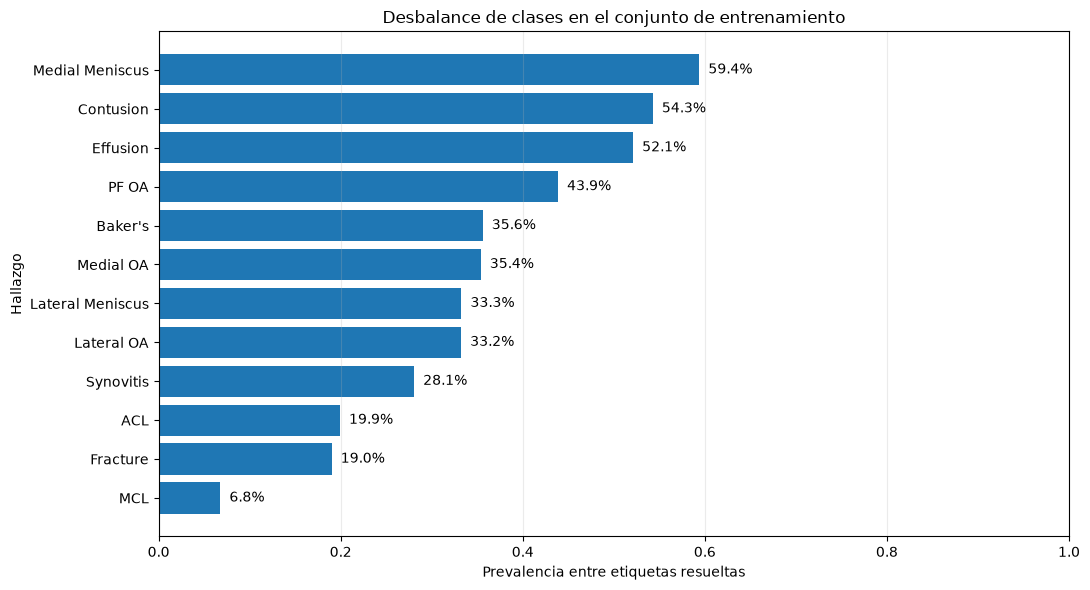

In [83]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(11, 6)
)

plt.barh(
    df_desbalance_ordenado[
        "Hallazgo"
    ],
    df_desbalance_ordenado[
        "Prevalencia_resuelta"
    ]
)

plt.xlabel(
    "Prevalencia entre etiquetas resueltas"
)

plt.ylabel(
    "Hallazgo"
)

plt.title(
    "Desbalance de clases en el conjunto de entrenamiento"
)

plt.xlim(
    0,
    1
)

plt.grid(
    axis="x",
    alpha=0.25
)

for i, valor in enumerate(
    df_desbalance_ordenado[
        "Prevalencia_resuelta"
    ]
):

    plt.text(
        valor + 0.01,
        i,
        f"{valor * 100:.1f}%",
        va="center"
    )

plt.tight_layout()

RUTA_PREVALENCIA = (
    OUTPUT_DIR / "prevalencia_clases_entrenamiento.png"
)

plt.savefig(
    RUTA_PREVALENCIA,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Gráfico de los pesos utilizados

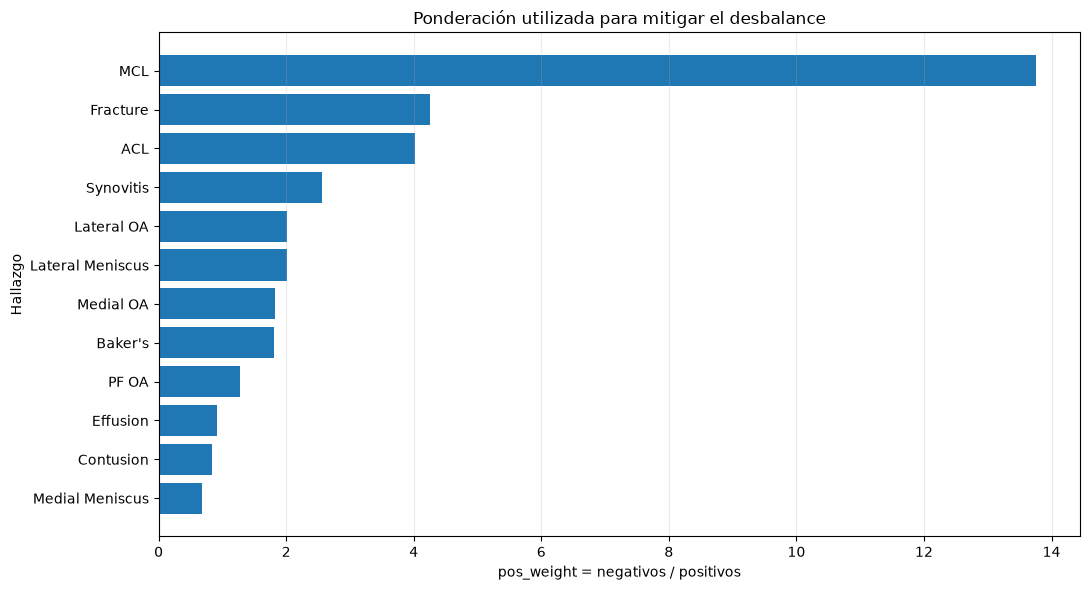

In [84]:
df_pesos = (
    df_desbalance
    .sort_values(
        "Pos_weight"
    )
)

plt.figure(
    figsize=(11, 6)
)

plt.barh(
    df_pesos[
        "Hallazgo"
    ],
    df_pesos[
        "Pos_weight"
    ]
)

plt.xlabel(
    "pos_weight = negativos / positivos"
)

plt.ylabel(
    "Hallazgo"
)

plt.title(
    "Ponderación utilizada para mitigar el desbalance"
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()

RUTA_PESOS = (
    OUTPUT_DIR / "pos_weight_por_hallazgo.png"
)

plt.savefig(
    RUTA_PESOS,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [85]:
RUTA_DESBALANCE = (
    OUTPUT_DIR / "analisis_desbalance_clases.csv"
)

df_desbalance.to_csv(
    RUTA_DESBALANCE,
    index=False
)

print("✅ Análisis de desbalance guardado:", RUTA_DESBALANCE)

✅ Análisis de desbalance guardado: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\analisis_desbalance_clases.csv


### Interpretación del desbalance

El conjunto de entrenamiento presenta un desbalance considerable entre los
doce hallazgos. MCL es la clase positiva más infrecuente, con una prevalencia
de 6.78 % entre las etiquetas resueltas, seguida por Fracture (19.00 %) y ACL
(19.91 %). En contraste, Medial Meniscus, Contusion y Effusion presentan
prevalencias superiores al 50 %.

Además del desbalance, la cobertura de supervisión débil varía de forma
importante entre hallazgos. ACL alcanza una cobertura del 93.27 %, mientras que
Medial OA y Synovitis presentan coberturas cercanas al 56 %, debido a una mayor
cantidad de abstenciones (-1).

Para mitigar el desbalance se utilizó una ponderación positiva por clase
(`pos_weight = negativos / positivos`) junto con Focal Loss. Esto asigna mayor
importancia a los positivos de clases poco frecuentes y reduce la contribución
relativa de ejemplos fáciles.

La clase MCL recibió el mayor peso positivo (13.76), seguida por Fracture
(4.26) y ACL (4.02). En la ablación controlada, manteniendo constantes los
pesos por clase, Focal Loss mejoró el AUC-ROC macro de 0.7360 a 0.7541 frente
a BCE ponderada, lo que sugiere un beneficio adicional del mecanismo focal
para este escenario desbalanceado.

## Riesgo de sesgo geográfico y lingüístico

El conjunto de datos reúne estudios provenientes de múltiples centros y regiones
geográficas, con reportes radiológicos redactados en varios idiomas. Esta
heterogeneidad introduce una fuente adicional de sesgo debido a que las etiquetas
de entrenamiento no fueron anotadas manualmente, sino extraídas automáticamente
a partir del texto clínico.

La calidad de la supervisión débil puede variar entre idiomas por diferencias en
terminología médica, abreviaturas, estructuras de negación y convenciones propias
de cada centro. Por ejemplo, un hallazgo puede describirse mediante expresiones
diferentes según el idioma o la institución, mientras que una regla basada en
palabras clave puede reconocer correctamente una formulación y abstenerse o
equivocarse ante otra.

Esta limitación se observa en la validación del extractor de etiquetas. En el
conjunto DEV se obtuvo una cobertura media de 61.9 %, acuerdo de 92.8 % y ruido
estimado de 7.2 %. Sin embargo, sobre un conjunto GOLD independiente, la cobertura
disminuyó a 36.6 %, el acuerdo a 73.9 % y el ruido aumentó a 26.1 %. Debido al
reducido número de estudios GOLD, esta diferencia no puede atribuirse
exclusivamente al idioma, pero evidencia que las reglas no generalizan de forma
uniforme a nuevas formulaciones clínicas.

Este problema puede propagarse al clasificador de imágenes. Si determinados
idiomas o centros producen etiquetas débiles de menor calidad, sus estudios
aportarán una supervisión más ruidosa y el modelo podría aprender patrones con
calidad desigual entre poblaciones.

En un despliegue clínico real sería necesario evaluar el extractor y el modelo
por idioma, centro y región, incorporar revisión de hablantes o radiólogos
locales, mantener mecanismos de abstención cuando el texto sea ambiguo y realizar
validación externa antes de utilizar el sistema en una nueva institución. También
sería recomendable reemplazar progresivamente las reglas rígidas por modelos
multilingües validados clínicamente y monitorear posibles diferencias de
rendimiento entre subgrupos.

In [86]:
test_dataset = KneeDataset(
    test_df,
    images,
    LABELS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(
    "HOLDOUT:",
    len(test_dataset)
)

HOLDOUT: 17


In [87]:
probs_test, y_test = obtener_predicciones(
    modelo_final,
    test_loader,
    device
)

print(
    "Probabilidades HOLDOUT:",
    probs_test.shape
)

print(
    "Targets HOLDOUT:",
    y_test.shape
)

Probabilidades HOLDOUT: (17, 12)
Targets HOLDOUT: (17, 12)


In [88]:
pred_test = (
    probs_test >= UMBRAL_FINAL
).astype(int)

metricas_holdout = []

for j, label in enumerate(LABELS):

    y_true = y_test[:, j].astype(int)
    y_pred = pred_test[:, j]
    y_prob = probs_test[:, j]

    positivos = int(
        (y_true == 1).sum()
    )

    negativos = int(
        (y_true == 0).sum()
    )

    # Con solo 17 estudios puede haber clases
    # sin positivos o sin negativos.
    if len(np.unique(y_true)) == 2:

        auc = roc_auc_score(
            y_true,
            y_prob
        )

    else:

        auc = np.nan

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    metricas_holdout.append(
        {
            "Hallazgo": label,
            "Positivos": positivos,
            "Negativos": negativos,
            "AUC": auc,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        }
    )

metricas_holdout = pd.DataFrame(
    metricas_holdout
)

display(
    metricas_holdout.round(4)
)

,Hallazgo,Positivos,Negativos,AUC,Precision,Recall,F1
0,ACL,7,10,0.8429,0.8000,0.5714,0.6667
1,MCL,3,14,0.2143,0.0000,0.0000,0.0000
2,Medial Meniscus,7,10,0.7143,0.5556,0.7143,0.6250
3,Lateral Meniscus,7,10,0.7143,0.6000,0.8571,0.7059
4,Medial OA,5,12,0.8500,0.4444,0.8000,0.5714
5,Lateral OA,3,14,0.8571,0.6000,1.0000,0.7500
6,PF OA,7,10,0.6857,0.7143,0.7143,0.7143
7,Effusion,7,10,0.9000,0.5455,0.8571,0.6667
8,Synovitis,7,10,0.8857,0.5455,0.8571,0.6667
9,Baker's,3,14,0.7143,0.2857,0.6667,0.4000


In [89]:
auc_validos = (
    metricas_holdout[
        "AUC"
    ]
    .notna()
    .sum()
)

resumen_holdout = pd.DataFrame({
    "Métrica": [
        "AUC macro",
        "Precision macro",
        "Recall macro",
        "F1 macro",
        "Etiquetas con AUC válido"
    ],

    "Valor": [
        metricas_holdout["AUC"].mean(),
        metricas_holdout["Precision"].mean(),
        metricas_holdout["Recall"].mean(),
        metricas_holdout["F1"].mean(),
        auc_validos
    ]
})

display(
    resumen_holdout.round(4)
)

,Métrica,Valor
0,AUC macro,0.7107
1,Precision macro,0.4891
2,Recall macro,0.7032
3,F1 macro,0.5639
4,Etiquetas con AUC válido,12.0000


In [90]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

metricas_holdout.to_csv(
    OUTPUT_DIR / "metricas_modelo_final_holdout.csv",
    index=False
)

resumen_holdout.to_csv(
    OUTPUT_DIR / "resumen_modelo_final_holdout.csv",
    index=False
)

np.save(
    OUTPUT_DIR / "probabilidades_holdout.npy",
    probs_test
)

print("✅ Evaluación HOLDOUT guardada en:", OUTPUT_DIR)

✅ Evaluación HOLDOUT guardada en: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation


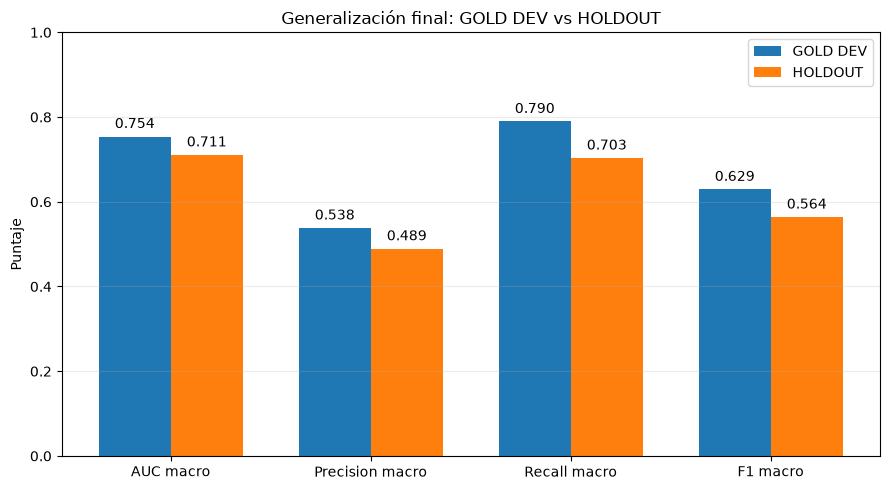

✅ Gráfico final guardado: C:\Users\PC\Documents\RSNA_Knee\processed\evaluation_ablation\dev_vs_holdout_final.png


In [91]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# COMPARACIÓN FINAL: GOLD DEV VS HOLDOUT
# ============================================================

metricas = [
    "AUC macro",
    "Precision macro",
    "Recall macro",
    "F1 macro"
]

# Recuperar las métricas realmente calculadas
dev = (
    resumen_macro
    .set_index("Métrica")
    .loc[metricas, "Valor"]
    .to_numpy(dtype=float)
)

holdout = (
    resumen_holdout
    .set_index("Métrica")
    .loc[metricas, "Valor"]
    .to_numpy(dtype=float)
)

x = np.arange(len(metricas))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    dev,
    width,
    label="GOLD DEV"
)

ax.bar(
    x + width / 2,
    holdout,
    width,
    label="HOLDOUT"
)

ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.set_ylim(0, 1)
ax.set_ylabel("Puntaje")
ax.set_title("Generalización final: GOLD DEV vs HOLDOUT")
ax.grid(axis="y", alpha=0.25)
ax.legend()

for i, valor in enumerate(dev):
    ax.text(
        i - width / 2,
        valor + 0.02,
        f"{valor:.3f}",
        ha="center"
    )

for i, valor in enumerate(holdout):
    ax.text(
        i + width / 2,
        valor + 0.02,
        f"{valor:.3f}",
        ha="center"
    )

plt.tight_layout()

RUTA_GRAFICO_FINAL = (
    OUTPUT_DIR / "dev_vs_holdout_final.png"
)

plt.savefig(
    RUTA_GRAFICO_FINAL,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Gráfico final guardado:", RUTA_GRAFICO_FINAL)

### Evaluación final sobre HOLDOUT

Después de congelar la arquitectura, el plano de MRI, la función de pérdida
y el umbral de decisión utilizando únicamente GOLD DEV, se realizó una única
evaluación final sobre los 17 estudios HOLDOUT.

El modelo alcanzó un AUC-ROC macro de 0.7107, frente a 0.7541 en GOLD DEV.
También se observó una reducción de F1 macro de 0.6293 a 0.5639.

Esta caída indica una brecha de generalización moderada y debe interpretarse
considerando el reducido tamaño del HOLDOUT, donde cada estudio tiene una
influencia importante sobre las métricas por clase.

El desempeño fue especialmente bajo para MCL y Contusion, mientras que
Fracture, Effusion, Synovitis, Lateral OA, Medial OA y ACL conservaron AUC
elevados. En particular, el bajo rendimiento de MCL es consistente con su
fuerte desbalance durante el entrenamiento.

Estos resultados se consideran finales y no se realizaron ajustes adicionales
del modelo ni del umbral después de observar el HOLDOUT.